<a href="https://colab.research.google.com/github/luiskeine/ColabNotes/blob/main/applied_machine_learning_feature_engineering_3809062.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature Engineering & Basic Machine Learning Techniques

## Table of Contents
1. [Basic Techniques](#Basic-Techniques)
    - [Imputation](#Imputation)
    - [Load Data](#Load-Data)
    - [Filling in Missing Values](#Filling-in-Missing-Values)
2. [Binning](#Binning)
3. [Log Transform](#Log-Transform)
4. [Scaling](#Scaling)
    - [Challenge: Basic Techniques](#Challenge:-Basic-Techniques)
5. [Categorical Encoding](#Categorical-Encoding)
    - [One Hot Encoding](#One-Hot-Encoding)
    - [Categorical Challenge](#Categorical-Challenge)
6. [Feature Extraction](#Feature-Extraction)
    - [PCA](#PCA)
    - [Feature Aggregation](#Feature-Aggregation)
    - [TFIDF](#TFIDF)
    - [Text Embeddings](#Text-Embeddings)
    - [Challenge: Feature Extraction](#Challenge:-Feature-Extraction)
7. [Temporal Features](#Temporal-Features)
    - [Extracting Date and Time Features](#Extracting-Date-and-Time-Features)
    - [Seasonality and Trend](#Seasonality-and-Trend)
    - [Challenge: Temporal Features](#Challenge:-Temporal-Features)
8. [Feature Selection](#Feature-Selection)
    - [Feature Importance and Weights](#Feature-Importance-and-Weights)
    - [Recursive Feature Elimination](#Recursive-Feature-Elimination)
    - [Adding a Random Column](#Adding-a-Random-Column)
    - [Challenge: Feature Selection](#Challenge:-Feature-Selection)
9. [Conclusion](#Conclusion:-What-I-Learned)

# Basic Techniques
# Imputation
Imputation means to fill in missing values with plausible values. There are many options:

- A constant value that has meaning within the domain, such as 0, distinct from all other values.
- A value from another randomly selected record.
- A mean, median or mode value for the column.
- A value estimated by another predictive model.

We use imputation because many machine learning algorithms do not support missing values. Modern algorithms like XGBoost handle missing values themselves, but it is still a common practice to impute because other algorithms do not.

# Load Data
Fuel economy data from the U.S. Environmental Protection Agency (EPA) for 2019 model year vehicles. The data are available in a CSV file with 82,000 rows and 83 columns.

https://www.fueleconomy.gov/feg/epadata/vehicles.csv

In [ ]:
!pip install pyarrow

In [ ]:
import pandas as pd
url = 'https://www.fueleconomy.gov/feg/epadata/vehicles.csv'

raw = pd.read_csv(url)#, dtype_backend='pyarrow', engine='pyarrow')

/tmp/ipykernel_358/2024954661.py:4: DtypeWarning: Columns (71,72,73,74,75,77,80) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(url)#, dtype_backend='pyarrow', engine='pyarrow')


In [ ]:
raw

,barrels08,barrelsA08,charge120,charge240,city08,city08U,cityA08,cityA08U,cityCD,cityE,...,mfrCode,c240Dscr,charge240b,c240bDscr,createdOn,modifiedOn,startStop,phevCity,phevHwy,phevComb
0,14.167143,0.0,0.0,0.0,19,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
1,27.046364,0.0,0.0,0.0,9,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
2,11.018889,0.0,0.0,0.0,23,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
3,27.046364,0.0,0.0,0.0,10,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
4,15.658421,0.0,0.0,0.0,17,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,13.523182,0.0,0.0,0.0,19,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50643,12.935217,0.0,0.0,0.0,20,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50644,14.167143,0.0,0.0,0.0,18,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0
50645,14.167143,0.0,0.0,0.0,18,0.0,0,0.0,0.0,0.0,...,NaN,NaN,0.0,NaN,Tue Jan 01 00:00:00 EST 2013,Tue Jan 01 00:00:00 EST 2013,NaN,0,0,0


In [ ]:
raw.columns

Index(['barrels08', 'barrelsA08', 'charge120', 'charge240', 'city08',
       'city08U', 'cityA08', 'cityA08U', 'cityCD', 'cityE', 'cityUF', 'co2',
       'co2A', 'co2TailpipeAGpm', 'co2TailpipeGpm', 'comb08', 'comb08U',
       'combA08', 'combA08U', 'combE', 'combinedCD', 'combinedUF', 'cylinders',
       'displ', 'drive', 'engId', 'eng_dscr', 'feScore', 'fuelCost08',
       'fuelCostA08', 'fuelType', 'fuelType1', 'ghgScore', 'ghgScoreA',
       'highway08', 'highway08U', 'highwayA08', 'highwayA08U', 'highwayCD',
       'highwayE', 'highwayUF', 'hlv', 'hpv', 'id', 'lv2', 'lv4', 'make',
       'model', 'mpgData', 'phevBlended', 'pv2', 'pv4', 'range', 'rangeCity',
       'rangeCityA', 'rangeHwy', 'rangeHwyA', 'trany', 'UCity', 'UCityA',
       'UHighway', 'UHighwayA', 'VClass', 'year', 'youSaveSpend', 'baseModel',
       'guzzler', 'trans_dscr', 'tCharger', 'sCharger', 'atvType', 'fuelType2',
       'rangeA', 'evMotor', 'mfrCode', 'c240Dscr', 'charge240b', 'c240bDscr',
       'createdOn'

In [ ]:
cols = ['year', 'make', 'model', 'trany', 'drive', 'VClass', 'eng_dscr',
    'barrels08', 'city08', 'comb08', 'range', 'evMotor', 'cylinders', 'displ', 'fuelCost08',
        'fuelType', 'highway08',  'trans_dscr','createdOn']

def to_tz(df_, time_col, tz_offset, tz_name):
    return (df_
            .groupby(tz_offset)
            [time_col]
            .transform(lambda s: pd.to_datetime(s)
                       .dt.tz_localize(s.name, ambiguous=True)
                       .dt.tz_convert(tz_name))
            )

autos = (raw.loc[:, cols]
         .assign(
            offset=(raw.createdOn.str.extract(r'\d\d:\d\d (?P<offset>[A-Z]{3}?)')
                .replace('EDT', 'EST5EDT')),
            str_date=(raw.createdOn.str.slice(4,19) + ' ' +
                raw.createdOn.str.slice(-4)),
            createdOn=lambda df_: to_tz(df_, 'str_date', 'offset', 'America/New_York')
         )
)
autos.dtypes

,0
year,int64
make,object
model,object
trany,object
drive,object
VClass,object
eng_dscr,object
barrels08,float64
city08,int64
comb08,int64


In [ ]:
True + 41

42

In [ ]:
False + 41

41

In [ ]:
# determining missing values
(autos
 .isna()
 #.sum()
 #.mean().mul(100).round(1)
 )

,year,make,model,trany,drive,VClass,eng_dscr,barrels08,city08,comb08,...,evMotor,cylinders,displ,fuelCost08,fuelType,highway08,trans_dscr,createdOn,offset,str_date
0,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,True,False,False,False,...,True,False,False,False,False,False,True,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
50643,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False
50644,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
50645,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,True,False,False,False


In [ ]:
# determining missing values
(autos
 .isna()
 .sum()
 #.mean().mul(100).round(1)
 )

,0
year,0
make,0
model,0
trany,11
drive,1186
VClass,0
eng_dscr,18522
barrels08,0
city08,0
comb08,0


In [ ]:
# determining missing values
(autos
 .isna()
 #.sum()
 .mean().mul(100).round(1)
 )

,0
year,0.0
make,0.0
model,0.0
trany,0.0
drive,2.3
VClass,0.0
eng_dscr,36.6
barrels08,0.0
city08,0.0
comb08,0.0


In [ ]:
(raw
 #.select_dtypes('string[pyarrow]')
 .select_dtypes(object)
 .isna()
 .sum()
)

,0
drive,1186
eng_dscr,18522
fuelType,0
fuelType1,2
make,0
model,0
mpgData,240
trany,11
VClass,0
baseModel,0


# Filling in Missing Values

In [ ]:
# where are cylinders missing?

(autos
 .query('cylinders.isna()')
 )

,year,make,model,trany,drive,VClass,eng_dscr,barrels08,city08,comb08,...,evMotor,cylinders,displ,fuelCost08,fuelType,highway08,trans_dscr,createdOn,offset,str_date
7138,2000,Nissan,Altra EV,NaN,NaN,Midsize Station Wagons,NaN,0.0960,81,85,...,62 KW AC Induction,NaN,NaN,900,Electricity,91,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
7139,2000,Toyota,RAV4 EV,NaN,2-Wheel Drive,Sport Utility Vehicle - 2WD,NaN,0.1128,81,72,...,50 KW DC,NaN,NaN,1050,Electricity,64,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
8143,2001,Toyota,RAV4 EV,NaN,2-Wheel Drive,Sport Utility Vehicle - 2WD,NaN,0.1128,81,72,...,50 KW DC,NaN,NaN,1050,Electricity,64,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
8144,2001,Ford,Th!nk,NaN,NaN,Two Seaters,NaN,0.1248,74,65,...,27 KW AC Induction,NaN,NaN,1150,Electricity,58,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
8146,2001,Ford,Explorer USPS Electric,NaN,2-Wheel Drive,Sport Utility Vehicle - 2WD,NaN,0.2088,45,39,...,67 KW AC Induction,NaN,NaN,1950,Electricity,33,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45213,2026,Porsche,Cayenne Turbo Coupe Electric w/21in All-Season...,Automatic (A1),All-Wheel Drive,Standard Sport Utility Vehicle 4WD,NaN,0.0912,94,88,...,"175, 388 and 600 kW ACPM",NaN,NaN,850,Electricity,81,NaN,2026-11-03 00:00:00-05:00,EST,Nov 03 00:00:00 2026
45215,2026,Porsche,Cayenne Turbo Coupe Electric,Automatic (A1),All-Wheel Drive,Standard Sport Utility Vehicle 4WD,NaN,0.0936,92,86,...,"175, 388 and 600 kW ACPM",NaN,NaN,900,Electricity,80,NaN,2026-11-03 00:00:00-05:00,EST,Nov 03 00:00:00 2026
45216,2026,Porsche,Cayenne Turbo Electric,Automatic (A1),All-Wheel Drive,Standard Sport Utility Vehicle 4WD,NaN,0.0960,91,85,...,"175, 388 and 600 kW ACPM",NaN,NaN,900,Electricity,78,NaN,2026-11-03 00:00:00-05:00,EST,Nov 03 00:00:00 2026
45217,2026,Porsche,Cayenne Turbo Electric w/21in All-Season Tires,Automatic (A1),All-Wheel Drive,Standard Sport Utility Vehicle 4WD,NaN,0.0936,93,86,...,"175, 388 and 600 kW ACPM",NaN,NaN,900,Electricity,80,NaN,2026-11-03 00:00:00-05:00,EST,Nov 03 00:00:00 2026


In [ ]:
(autos
 .assign(cylinders=autos.cylinders.fillna(0))
)

,year,make,model,trany,drive,VClass,eng_dscr,barrels08,city08,comb08,...,evMotor,cylinders,displ,fuelCost08,fuelType,highway08,trans_dscr,createdOn,offset,str_date
0,1985,Alfa Romeo,Spider Veloce 2000,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(FFS),14.167143,19,21,...,NaN,4.0,2.0,2950,Regular,25,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
1,1985,Ferrari,Testarossa,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(GUZZLER),27.046364,9,11,...,NaN,12.0,4.9,5650,Regular,14,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
2,1985,Dodge,Charger,Manual 5-spd,Front-Wheel Drive,Subcompact Cars,(FFS),11.018889,23,27,...,NaN,4.0,2.2,2300,Regular,33,SIL,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
3,1985,Dodge,B150/B250 Wagon 2WD,Automatic 3-spd,Rear-Wheel Drive,Vans,NaN,27.046364,10,11,...,NaN,8.0,5.2,5650,Regular,12,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
4,1993,Subaru,Legacy AWD Turbo,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,"(FFS,TRBO)",15.658421,17,19,...,NaN,4.0,2.2,4050,Premium,23,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,1993,Subaru,Legacy,Automatic 4-spd,Front-Wheel Drive,Compact Cars,(FFS),13.523182,19,22,...,NaN,4.0,2.2,2850,Regular,26,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50643,1993,Subaru,Legacy,Manual 5-spd,Front-Wheel Drive,Compact Cars,(FFS),12.935217,20,23,...,NaN,4.0,2.2,2700,Regular,28,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50644,1993,Subaru,Legacy AWD,Automatic 4-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),14.167143,18,21,...,NaN,4.0,2.2,2950,Regular,24,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50645,1993,Subaru,Legacy AWD,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),14.167143,18,21,...,NaN,4.0,2.2,2950,Regular,24,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013


In [ ]:
# Create sklearn pipeline to fill in missing cylinders with 0

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# set output to pandas
from sklearn import set_config
set_config(transform_output='pandas')

# create pipeline for cylinders
cyl_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value=0)),
])

# try it out
cyl_pipe.fit_transform(autos[['cylinders']])

,cylinders
0,4.0
1,12.0
2,4.0
3,8.0
4,4.0
...,...
50642,4.0
50643,4.0
50644,4.0
50645,4.0


In [ ]:
# see where it fill in missing values
(cyl_pipe
 .fit_transform(autos[['cylinders']])
 .loc[autos.cylinders.isna()]
)

,cylinders
7138,0.0
7139,0.0
8143,0.0
8144,0.0
8146,0.0
...,...
45213,0.0
45215,0.0
45216,0.0
45217,0.0


In [ ]:
# create more realistic pipeline
# set missing cylinders to 0 and displ to median
from sklearn.compose import ColumnTransformer
cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ'])
    ],
    remainder='passthrough'
)

# Create the pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# Fit and transform the data
pipeline.fit_transform(autos)

,cyl_imputer__cylinders,displ_imputer__displ,remainder__year,remainder__make,remainder__model,remainder__trany,remainder__drive,remainder__VClass,remainder__eng_dscr,remainder__barrels08,...,remainder__comb08,remainder__range,remainder__evMotor,remainder__fuelCost08,remainder__fuelType,remainder__highway08,remainder__trans_dscr,remainder__createdOn,remainder__offset,remainder__str_date
0,4.0,2.0,1985,Alfa Romeo,Spider Veloce 2000,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(FFS),14.167143,...,21,0,NaN,2950,Regular,25,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
1,12.0,4.9,1985,Ferrari,Testarossa,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(GUZZLER),27.046364,...,11,0,NaN,5650,Regular,14,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
2,4.0,2.2,1985,Dodge,Charger,Manual 5-spd,Front-Wheel Drive,Subcompact Cars,(FFS),11.018889,...,27,0,NaN,2300,Regular,33,SIL,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
3,8.0,5.2,1985,Dodge,B150/B250 Wagon 2WD,Automatic 3-spd,Rear-Wheel Drive,Vans,NaN,27.046364,...,11,0,NaN,5650,Regular,12,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
4,4.0,2.2,1993,Subaru,Legacy AWD Turbo,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,"(FFS,TRBO)",15.658421,...,19,0,NaN,4050,Premium,23,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,4.0,2.2,1993,Subaru,Legacy,Automatic 4-spd,Front-Wheel Drive,Compact Cars,(FFS),13.523182,...,22,0,NaN,2850,Regular,26,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50643,4.0,2.2,1993,Subaru,Legacy,Manual 5-spd,Front-Wheel Drive,Compact Cars,(FFS),12.935217,...,23,0,NaN,2700,Regular,28,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50644,4.0,2.2,1993,Subaru,Legacy AWD,Automatic 4-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),14.167143,...,21,0,NaN,2950,Regular,24,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50645,4.0,2.2,1993,Subaru,Legacy AWD,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),14.167143,...,21,0,NaN,2950,Regular,24,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013


# Binning
Binning is a process of transforming continuous numerical variables into discrete categorical 'bins'. Binning is used for:

- Converting a continuous feature to a categorical feature
- Helping with non-linear relationships
- Reducing the effects of noise and outliers
- Handling missing values

<Axes: >

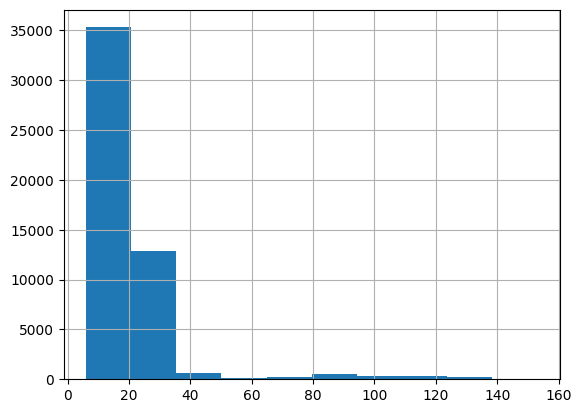

In [ ]:
# Create a histogram of city08

autos.city08.hist()

((array([-4.19430036, -3.98868783, -3.87659488, ...,  3.87659488,
          3.98868783,  4.19430036], shape=(50647,)),
  array([  6,   6,   6, ..., 151, 153, 153], shape=(50647,))),
 (np.float64(10.69329602711506),
  np.float64(21.191758643157538),
  np.float64(0.6714890052277075)))

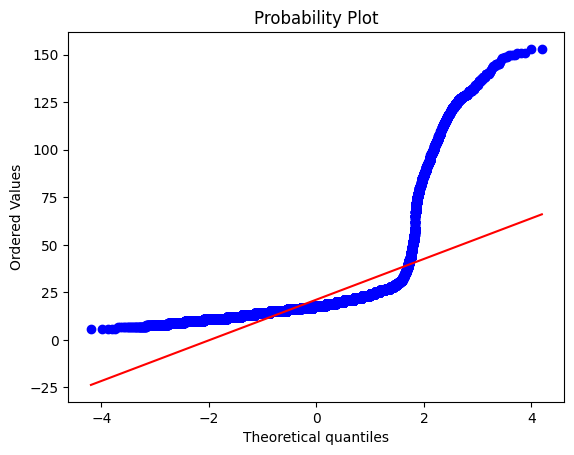

In [ ]:
# use a probability plot to see if it is normally distributed
from scipy import stats
from matplotlib import pyplot as plt

stats.probplot(autos.city08, plot=plt)

((array([-4.18403421, -3.97794236, -3.86556959, ...,  3.86556959,
          3.97794236,  4.18403421], shape=(48407,)),
  array([ 6,  6,  6, ..., 39, 39, 39], shape=(48407,))),
 (np.float64(4.611125538970274),
  np.float64(18.17978804718326),
  np.float64(0.9782944530807468)))

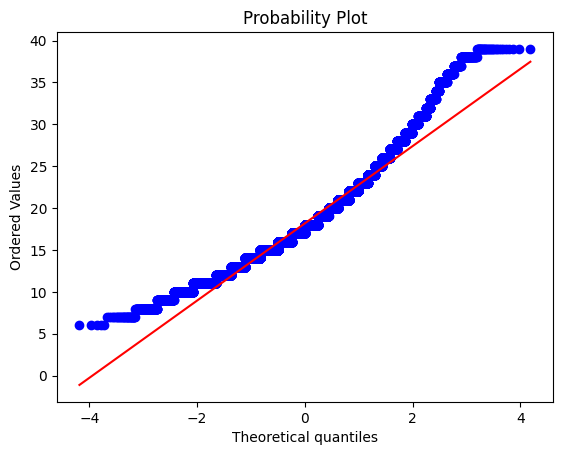

In [ ]:
stats.probplot(autos.query('city08 < 40').city08, plot=plt)
# Generates a Q-Q (quantile-quantile) probability plot for a filtered subset
# of vehicles with city mileage under 40 MPG to compare its distribution against
# a theoretical normal distribution (re-plotting after removing the high-MPG outliers).

In [ ]:
# bin the city08 data with pandas
pd.cut(autos.city08, bins=10)

,city08
0,"(5.853, 20.7]"
1,"(5.853, 20.7]"
2,"(20.7, 35.4]"
3,"(5.853, 20.7]"
4,"(5.853, 20.7]"
...,...
50642,"(5.853, 20.7]"
50643,"(5.853, 20.7]"
50644,"(5.853, 20.7]"
50645,"(5.853, 20.7]"


<Axes: xlabel='city08'>

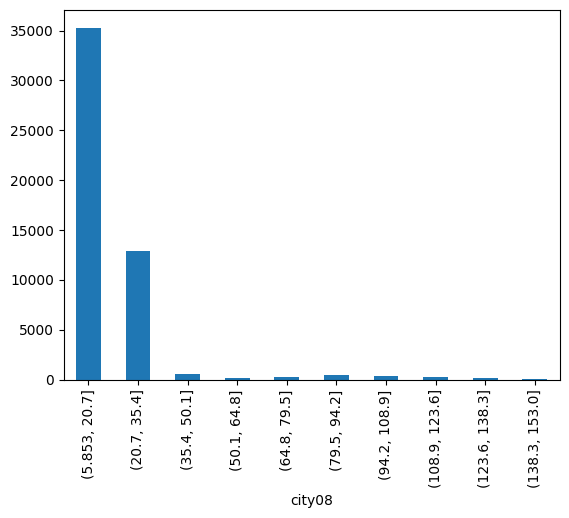

In [ ]:
(pd.cut(autos.city08, bins=10)
 .value_counts()
 .sort_index()
  .plot.bar()
)

<Axes: xlabel='city08'>

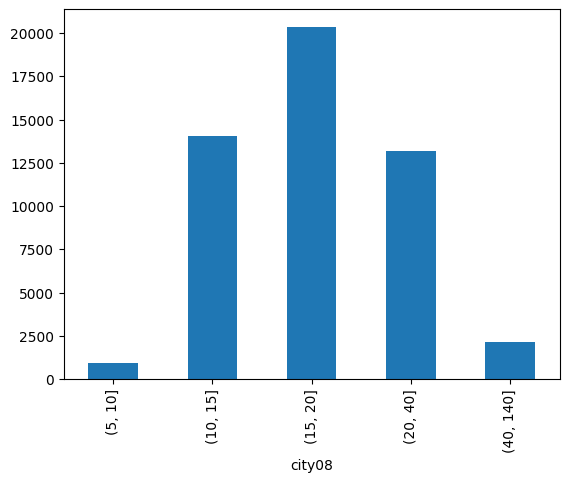

In [ ]:
# manually create edges for bins
(pd.cut(autos.city08, bins=[5,10,15,20,40, 140])
 .value_counts()
 .sort_index()
 .plot.bar()
)

In [ ]:
# binning with sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import KBinsDiscretizer

# Define the binning strategy
binning_strategy = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')

column_transformer = ColumnTransformer(
    transformers=[
        ('binning', binning_strategy, ['city08'])
    ],
    remainder='passthrough'  # This ensures other columns are left unchanged
)


pipeline = Pipeline(steps=[('transformer', column_transformer)])
pipeline.fit_transform(autos)

,binning__city08,remainder__year,remainder__make,remainder__model,remainder__trany,remainder__drive,remainder__VClass,remainder__eng_dscr,remainder__barrels08,remainder__comb08,...,remainder__evMotor,remainder__cylinders,remainder__displ,remainder__fuelCost08,remainder__fuelType,remainder__highway08,remainder__trans_dscr,remainder__createdOn,remainder__offset,remainder__str_date
0,3.0,1985,Alfa Romeo,Spider Veloce 2000,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(FFS),14.167143,21,...,NaN,4.0,2.0,2950,Regular,25,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
1,0.0,1985,Ferrari,Testarossa,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(GUZZLER),27.046364,11,...,NaN,12.0,4.9,5650,Regular,14,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
2,4.0,1985,Dodge,Charger,Manual 5-spd,Front-Wheel Drive,Subcompact Cars,(FFS),11.018889,27,...,NaN,4.0,2.2,2300,Regular,33,SIL,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
3,0.0,1985,Dodge,B150/B250 Wagon 2WD,Automatic 3-spd,Rear-Wheel Drive,Vans,NaN,27.046364,11,...,NaN,8.0,5.2,5650,Regular,12,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
4,2.0,1993,Subaru,Legacy AWD Turbo,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,"(FFS,TRBO)",15.658421,19,...,NaN,4.0,2.2,4050,Premium,23,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,3.0,1993,Subaru,Legacy,Automatic 4-spd,Front-Wheel Drive,Compact Cars,(FFS),13.523182,22,...,NaN,4.0,2.2,2850,Regular,26,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50643,3.0,1993,Subaru,Legacy,Manual 5-spd,Front-Wheel Drive,Compact Cars,(FFS),12.935217,23,...,NaN,4.0,2.2,2700,Regular,28,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50644,2.0,1993,Subaru,Legacy AWD,Automatic 4-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),14.167143,21,...,NaN,4.0,2.2,2950,Regular,24,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50645,2.0,1993,Subaru,Legacy AWD,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),14.167143,21,...,NaN,4.0,2.2,2950,Regular,24,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013


<Axes: xlabel='binning__city08'>

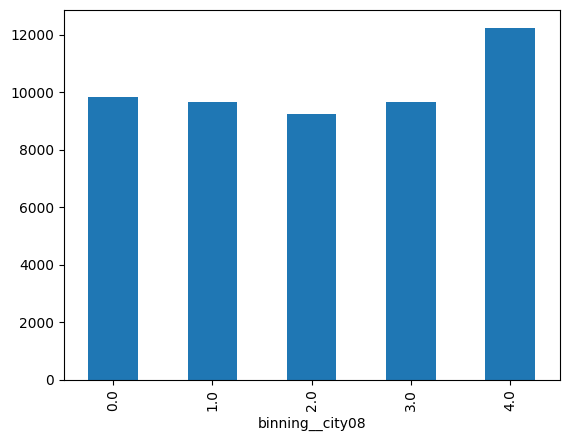

In [ ]:
pipeline.fit_transform(autos).binning__city08.value_counts().sort_index().plot.bar()

In [ ]:
# pipeline
cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
binning_strategy = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('binning', binning_strategy, ['city08'])
    ],
    remainder='passthrough'
)

# # Create the pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# # Fit and transform the data
pipeline.fit_transform(autos)

,cyl_imputer__cylinders,displ_imputer__displ,binning__city08,remainder__year,remainder__make,remainder__model,remainder__trany,remainder__drive,remainder__VClass,remainder__eng_dscr,...,remainder__comb08,remainder__range,remainder__evMotor,remainder__fuelCost08,remainder__fuelType,remainder__highway08,remainder__trans_dscr,remainder__createdOn,remainder__offset,remainder__str_date
0,4.0,2.0,3.0,1985,Alfa Romeo,Spider Veloce 2000,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(FFS),...,21,0,NaN,2950,Regular,25,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
1,12.0,4.9,0.0,1985,Ferrari,Testarossa,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(GUZZLER),...,11,0,NaN,5650,Regular,14,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
2,4.0,2.2,4.0,1985,Dodge,Charger,Manual 5-spd,Front-Wheel Drive,Subcompact Cars,(FFS),...,27,0,NaN,2300,Regular,33,SIL,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
3,8.0,5.2,0.0,1985,Dodge,B150/B250 Wagon 2WD,Automatic 3-spd,Rear-Wheel Drive,Vans,NaN,...,11,0,NaN,5650,Regular,12,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
4,4.0,2.2,2.0,1993,Subaru,Legacy AWD Turbo,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,"(FFS,TRBO)",...,19,0,NaN,4050,Premium,23,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,4.0,2.2,3.0,1993,Subaru,Legacy,Automatic 4-spd,Front-Wheel Drive,Compact Cars,(FFS),...,22,0,NaN,2850,Regular,26,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50643,4.0,2.2,3.0,1993,Subaru,Legacy,Manual 5-spd,Front-Wheel Drive,Compact Cars,(FFS),...,23,0,NaN,2700,Regular,28,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50644,4.0,2.2,2.0,1993,Subaru,Legacy AWD,Automatic 4-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),...,21,0,NaN,2950,Regular,24,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50645,4.0,2.2,2.0,1993,Subaru,Legacy AWD,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),...,21,0,NaN,2950,Regular,24,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013


In [ ]:
# replace pyarrow numbers with numpy numbers
cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
binning_strategy = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile')

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('binning', binning_strategy, ['city08'])
    ],
    remainder='passthrough'
)

# Create the pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# Fit and transform the data
pipeline.fit_transform(autos)

,cyl_imputer__cylinders,displ_imputer__displ,binning__city08,remainder__year,remainder__make,remainder__model,remainder__trany,remainder__drive,remainder__VClass,remainder__eng_dscr,...,remainder__comb08,remainder__range,remainder__evMotor,remainder__fuelCost08,remainder__fuelType,remainder__highway08,remainder__trans_dscr,remainder__createdOn,remainder__offset,remainder__str_date
0,4.0,2.0,3.0,1985,Alfa Romeo,Spider Veloce 2000,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(FFS),...,21,0,NaN,2950,Regular,25,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
1,12.0,4.9,0.0,1985,Ferrari,Testarossa,Manual 5-spd,Rear-Wheel Drive,Two Seaters,(GUZZLER),...,11,0,NaN,5650,Regular,14,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
2,4.0,2.2,4.0,1985,Dodge,Charger,Manual 5-spd,Front-Wheel Drive,Subcompact Cars,(FFS),...,27,0,NaN,2300,Regular,33,SIL,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
3,8.0,5.2,0.0,1985,Dodge,B150/B250 Wagon 2WD,Automatic 3-spd,Rear-Wheel Drive,Vans,NaN,...,11,0,NaN,5650,Regular,12,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
4,4.0,2.2,2.0,1993,Subaru,Legacy AWD Turbo,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,"(FFS,TRBO)",...,19,0,NaN,4050,Premium,23,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,4.0,2.2,3.0,1993,Subaru,Legacy,Automatic 4-spd,Front-Wheel Drive,Compact Cars,(FFS),...,22,0,NaN,2850,Regular,26,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50643,4.0,2.2,3.0,1993,Subaru,Legacy,Manual 5-spd,Front-Wheel Drive,Compact Cars,(FFS),...,23,0,NaN,2700,Regular,28,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50644,4.0,2.2,2.0,1993,Subaru,Legacy AWD,Automatic 4-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),...,21,0,NaN,2950,Regular,24,CLKUP,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013
50645,4.0,2.2,2.0,1993,Subaru,Legacy AWD,Manual 5-spd,4-Wheel or All-Wheel Drive,Compact Cars,(FFS),...,21,0,NaN,2950,Regular,24,NaN,2013-01-01 00:00:00-05:00,EST,Jan 01 00:00:00 2013


# Log Transform
Log transformation is a data transformation method in which it replaces each variable x with a log(x). This is useful when the data is skewed and you are using a model that assumes normality or linearity.

It is also common to use log transformation on the target variable y in regression

<Axes: xlabel='city08_log', ylabel='city08'>

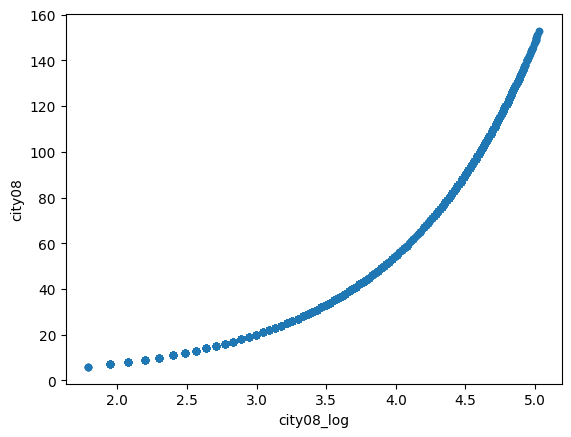

In [ ]:
# scatter plot to show log of city08 vs original
import numpy as np
(autos
    .assign(city08_log=np.log(autos.city08))
    .plot.scatter(x='city08_log', y='city08')
    )

<Axes: >

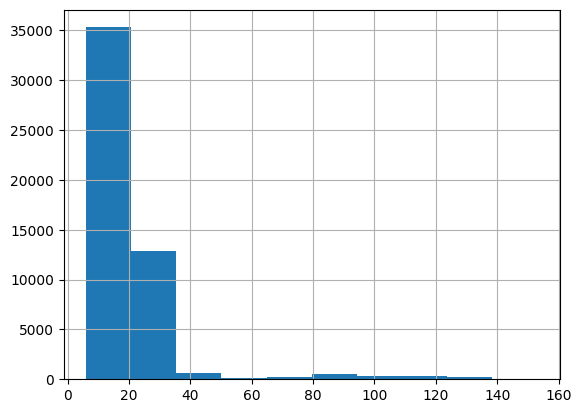

In [ ]:
autos.city08.hist()

<Axes: >

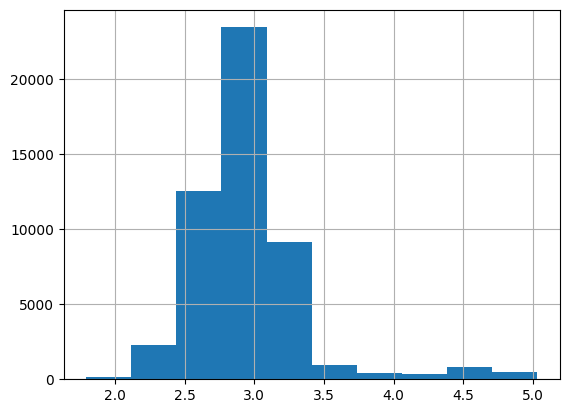

In [ ]:
# scatter plot to show log of city08 vs original

(autos
    .assign(city08_log=np.log(autos.city08))
    .city08_log.hist()
    )

In [ ]:
# Baseline model with linear regression to predict city08
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08']).select_dtypes('number')
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ'])])),
                ('lr', LinearRegression())])

In [ ]:
# score
pipeline.score(X_test, y_test)

0.8025061552032433

In [ ]:
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test, pipeline.predict(X_test))

4.138018787236534

In [ ]:
# try again with log transform of y
# create X and y
X = X
y_log = np.log(autos.city08)

# split into train and test
X_train, X_test, y_train_log, y_test_log = train_test_split(X, y_log, random_state=42)

# pipeline
pipeline_log = Pipeline(steps=[('preprocessor', preprocessor), ('lr', LinearRegression())])

# fit the pipeline
pipeline_log.fit(X_train, y_train_log)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ'])])),
                ('lr', LinearRegression())])

In [ ]:
pipeline_log.score(X_test, y_test_log)

0.9126330378169982

In [ ]:
# take exp of predictions and score the mean absolute error
from sklearn.metrics import mean_absolute_error

y_pred_log = np.exp(pipeline_log.predict(X_test))

mean_absolute_error(np.exp(y_test_log), y_pred_log)

2.0920937487529994

# Scaling
Scaling is an ambiguous term that generally means one of two things:

- Min-max scaling - Changing the range of a variable to be between 0 and 1 or -1 to 1.
- Standard scaling (Standardization) - Changing the distribution of a variable to have a mean of 0 and a standard deviation of 1.

We'll show examples of both below.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08']).select_dtypes('number')
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
    ],
    remainder='passthrough'
)

pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('std_scaler', std_scaler),
                           #('minmax_scaler', minmax_scaler),
                           ('lr', LinearRegression())])

pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ'])])),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

# Challenge: Basic Techniques
Predicting mileage from barrels08.

- Make a model to predict city08 from barrels08 using linear regression.
- What is the score?
- Scatter plot barrel08 vs city08
- Make a new model transforming barrels08 based on the results of the scatter plot.
- How does the new model perform?

In [ ]:
X = autos[['barrels08']]
y = autos['city08']

#split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train

#create a pipeline(optional)
pipeline = Pipeline(steps=[('lr', LinearRegression())])

#fit the pipeline
pipeline.fit(X_train, y_train)

#score
pipeline.score(X_test, y_test)



0.574479545314578

<Axes: xlabel='barrels08', ylabel='city08'>

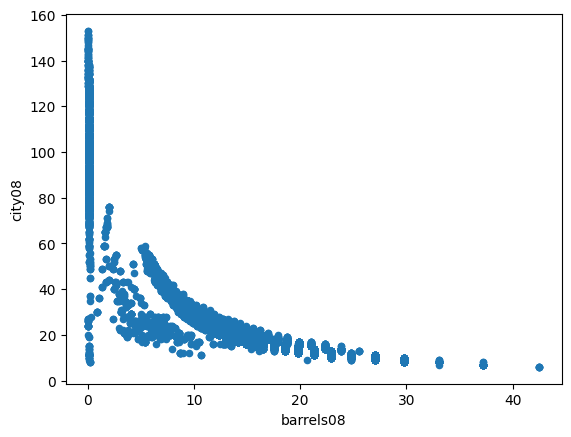

In [ ]:
(autos
 .plot.scatter(x='barrels08', y='city08'))

<Axes: xlabel='blog', ylabel='city08'>

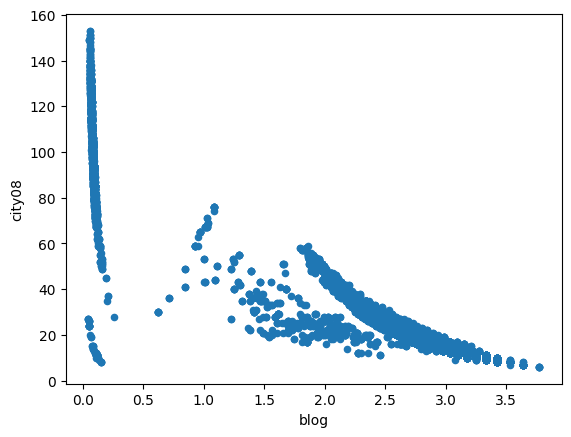

In [ ]:
(autos
 .assign(blog=np.log(autos.barrels08 + 1))
 .plot.scatter(x='blog', y='city08'))

In [ ]:
X = np.log(autos[['barrels08']] + 1)
y = autos['city08']

#split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train

#create a pipeline(optional)
pipeline = Pipeline(steps=[('lr', LinearRegression())])

#fit the pipeline
pipeline.fit(X_train, y_train)

#score
pipeline.score(X_test, y_test)



0.8874243867408557

# Categorical Encoding
# One Hot Encoding
Many ML algorithms cannot work with categorical data directly. The categories must be converted into numbers. This process is called encoding.

One of the most common encodings is one hot encoding, also called dummy encoding. This creates a new column for each category with a 1 or 0 value.

In [ ]:
autos.VClass

,VClass
0,Two Seaters
1,Two Seaters
2,Subcompact Cars
3,Vans
4,Compact Cars
...,...
50642,Compact Cars
50643,Compact Cars
50644,Compact Cars
50645,Compact Cars


In [ ]:
pd.get_dummies(autos.VClass)

,Compact Cars,Large Cars,Midsize Cars,Midsize Station Wagons,Midsize-Large Station Wagons,Minicompact Cars,Minivan - 2WD,Minivan - 4WD,Small Pickup Trucks,Small Pickup Trucks 2WD,...,Standard Pickup Trucks 4WD,Standard Pickup Trucks/2wd,Standard Sport Utility Vehicle 2WD,Standard Sport Utility Vehicle 4WD,Subcompact Cars,Two Seaters,Vans,Vans Passenger,"Vans, Cargo Type","Vans, Passenger Type"
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
50643,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
50644,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
50645,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
pd.get_dummies(autos.VClass, drop_first=True)

,Large Cars,Midsize Cars,Midsize Station Wagons,Midsize-Large Station Wagons,Minicompact Cars,Minivan - 2WD,Minivan - 4WD,Small Pickup Trucks,Small Pickup Trucks 2WD,Small Pickup Trucks 4WD,...,Standard Pickup Trucks 4WD,Standard Pickup Trucks/2wd,Standard Sport Utility Vehicle 2WD,Standard Sport Utility Vehicle 4WD,Subcompact Cars,Two Seaters,Vans,Vans Passenger,"Vans, Cargo Type","Vans, Passenger Type"
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
50643,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
50644,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
50645,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [ ]:
# Cardinality - number of unique values in a column
# probably don't want to make ~5k model columns
(autos
 .select_dtypes(object) # use 'string[pyarrow]' if using pyarrow types
 .nunique()
)

,0
make,146
model,5747
trany,40
drive,7
VClass,34
eng_dscr,628
evMotor,634
fuelType,16
trans_dscr,52
offset,2


In [ ]:
# Cardinality - number of unique values in a column
# probably don't want to make ~5k model columns
(autos
 .select_dtypes(object)
 .nunique()
 .index
)

Index(['make', 'model', 'trany', 'drive', 'VClass', 'eng_dscr', 'evMotor',
       'fuelType', 'trans_dscr', 'offset', 'str_date'],
      dtype='object')

In [ ]:
# categorical encoding in pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10)

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),

        ('one_hot_encoder', one_hot_encoder, ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ],),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                          ('std_scaler', std_scaler),
                           #  ('minmax_scaler', minmax_scaler, ['range']),
                           ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

#ValueError: Pandas output does not support sparse data. Set sparse_output=False to output pandas dataframes or disable Pandas output via` ohe.set_output(transform="default").


ValueError: Pandas output does not support sparse data. Set sparse_output=False to output pandas dataframes or disable Pandas output via` ohe.set_output(transform="default").

In [ ]:
# Impute missing values AND convert Pandas 2 strings to Pandas 1 strings
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder

X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False)

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('cat_imputer', cat_imputer, cat_cols),
        ('one_hot_encoder', one_hot_encoder, cat_cols),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                          ('std_scaler', std_scaler),
                           #  ('minmax_scaler', minmax_scaler, ['range']),
                           ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train.assign(**X_train.select_dtypes('string[pyarrow]').astype(str)), y_train)

#ValueError: could not convert string to float: 'Subaru'

ValueError: could not convert string to float: 'Subaru'

In [ ]:
# Debug with FunctionTransformer
# And figure out that I need a separate pipeline for categorical columns
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder

X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]

cat_pipe = Pipeline([
    ('cat_imputer', cat_imputer),
    ('one_hot_encoder', one_hot_encoder)
])

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('cat_pl', cat_pipe, cat_cols),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
                           ('std_scaler', std_scaler),
                           #  ('minmax_scaler', minmax_scaler, ['range']),
                           ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ']),
                                                 ('cat_pl',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('one_hot_encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 max_categories=10,
                                                                                 sparse_output=False))]),
                                                  ['make', 'model', 'trany',
                                                   'drive', 'VClass',
                                                   'eng_dscr', 'evMotor',
                                                   'fuelType',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf520adf420>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
tmp_X

,cyl_imputer__cylinders,displ_imputer__displ,cat_pl__make_Chevrolet,cat_pl__make_Dodge,cat_pl__make_Ford,cat_pl__make_GMC,cat_pl__make_Mercedes-Benz,cat_pl__make_Nissan,cat_pl__make_Porsche,cat_pl__make_Toyota,...,cat_pl__trans_dscr_CLKUP,cat_pl__trans_dscr_Creeper,cat_pl__trans_dscr_EMS 2MODE CLKUP,cat_pl__trans_dscr_SIL,cat_pl__trans_dscr_missing,cat_pl__trans_dscr_infrequent_sklearn,remainder__year,remainder__barrels08,remainder__range,remainder__fuelCost08
45613,6.0,2.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1989,15.658421,0,3300
9440,6.0,2.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,2003,14.167143,0,2950
26317,6.0,3.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2014,14.875500,0,3100
18874,4.0,2.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1984,14.875500,0,3100
34507,10.0,5.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2020,18.594375,0,4850
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,8.0,5.3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,2004,19.834000,0,4150
44732,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2027,0.112800,338,1050
38158,8.0,5.3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,2022,16.528333,0,3450
860,6.0,2.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1994,14.875500,0,3850


In [ ]:
pipeline.score(X_test, y_test)

#ValueError: Found unknown categories ['Qvale', 'Mahindra', 'Lordstown', 'Red Shift Ltd.', 'S and S Coach Company  E.p. Dutton'] in column 0 during transform


ValueError: Found unknown categories ['Lordstown', 'S and S Coach Company  E.p. Dutton', 'Red Shift Ltd.', 'Qvale', 'Mahindra'] in column 0 during transform

In [ ]:
# Deal with missing categories in test set w/ handle_unknown='ignore'
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder

X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Add handle_unknown='ignore' to OneHotEncoder
# one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False)
cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]

cat_pipe = Pipeline([
    ('cat_imputer', cat_imputer),
    ('one_hot_encoder', one_hot_encoder)
])

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('cat_pl', cat_pipe, cat_cols),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
                          ('std_scaler', std_scaler),
                           #  ('minmax_scaler', minmax_scaler, ['range']),
                           ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ']),
                                                 ('cat_pl',
                                                  Pipeline(steps=[('cat_imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('one_hot_encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 max_categories=10,
                                                                                 sparse_output=False))]),
                                                  ['make', 'model', 'trany',
                                                   'drive', 'VClass',
                                                   'eng_dscr', 'evMotor',
                                                   'fuelType',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf520adf600>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1, 5, 6, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


0.9352050363415577

#Hash Encoding
Hash encoding is a technique that can be used when there are too many categories to encode with one hot encoding. It is similar to one hot encoding, but the categories are hashed into a smaller number of columns.

We are going to use the category_encoders library to do the encoding. This library has many other encoders that you can explore.

In [ ]:
!pip install category_encoders

In [ ]:
(autos
 .select_dtypes(object)
 .nunique()
)

,0
make,146
model,5747
trany,40
drive,7
VClass,34
eng_dscr,628
evMotor,634
fuelType,16
trans_dscr,52
offset,2


In [ ]:
(autos
 .select_dtypes(object)
 .nunique()
 .pipe(lambda s: s[s > 40])
 .index
)

Index(['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr', 'str_date'], dtype='object')

In [ ]:
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

In [ ]:
# low cardinality columns
(autos
 .select_dtypes(object)
 .nunique()
 .index
 .difference(high_cardinality_cols)
)

Index(['VClass', 'drive', 'fuelType', 'offset', 'str_date', 'trany'], dtype='object')

In [ ]:
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']

In [ ]:
# replace one hot encoder with hashing encoder for high cardinality columns
from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder

X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# add hashing encoder
cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        #('cat_pl', cat_pipe, cat_cols),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        ('hashing_encoder', hashing_encoder, high_cardinality_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
                          ('std_scaler', std_scaler),
                           #  ('minmax_scaler', minmax_scaler, ['range']),
                           ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ']),
                                                 ('one_hot_encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                max_categories=10,
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('hashing_encoder',
                                                  HashingEncoder(drop_invariant=True,
                                                                 max_process=1,
                                                                 n_components=10),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf521056f20>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

#Target Encoding
From docstring: [In Target Encoding] Each category is encoded based on a shrunk estimate of the average target values for observations belonging to the category. The encoding scheme mixes the global target mean with the target mean conditioned on the value of the category.

In [ ]:
from sklearn.preprocessing import TargetEncoder

te = TargetEncoder(target_type='continuous', random_state=42)
te.fit_transform(X_train[['make']], y_train)

,make
45613,22.785235
9440,17.831434
26317,23.885360
18874,17.883733
34507,22.305124
...,...
11284,17.695074
44732,82.052639
38158,17.767234
860,20.728539


In [ ]:
# replace hashing encoder with target encoder for high cardinality columns
from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder

# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median
cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
                          ('std_scaler', std_scaler),
                           #  ('minmax_scaler', minmax_scaler, ['range']),
                           ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ']),
                                                 ('one_hot_encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                max_categories=10,
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf50a43e3e0>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
X = autos[['barrels08']]
y = autos['city08']

# split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

pipeline = Pipeline(steps=[('lr', LinearRegression())])

pipeline.fit(X_train, y_train)
pipeline.score(X_test, y_test)

0.574479545314578

In [ ]:
pipeline.score(X_test.assign(**X_test.select_dtypes('string[pyarrow]').astype(str)),
                y_test)

0.574479545314578

In [ ]:
# make a custom class transformer to remove PyArrow strings (if using PyArrow)
from sklearn.base import BaseEstimator, TransformerMixin

class PyArrowStringConverter(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.assign(**X.select_dtypes('string[pyarrow]').astype(str))

In [ ]:
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('preprocessor', preprocessor),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    ('std_scaler', std_scaler),
    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ']),
                                                 ('one_hot_encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                max_cat...
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf521056fc0>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

0.9528148954811413

#Categorical Challenge
Create a model to predict mileage using only the categorical columns (dropping the model column)

cat_cols = ['trany', 'drive', 'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr']
#Solution: Categorical Challenge

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn import set_config

# set output to pandas
set_config(transform_output='pandas')

# Create X and y

cat_cols = ['trany', 'drive', 'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr']

# Create X and y
X = (autos
     .loc[:, cat_cols])
y = autos.city08

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create column transformer with one hot encoder
# from sklearn.compose import ColumnTransformer
# from sklearn.preprocessing import OneHotEncoder

# create a pipeline
cat_transformer = ColumnTransformer(
    transformers=[
        ('one_hot_encoder', OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore'), cat_cols)
    ],
    remainder='passthrough'
)

# fit the pipeline
pipeline = Pipeline(steps=[
    ('cat_transformer', cat_transformer),
    ('lr', LinearRegression())
])

pipeline.fit(X_train, y_train)

# score the pipeline
pipeline.score(X_test, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [3, 4, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


0.8996938709340458

#Feature Extraction
Feature extraction is the process of transforming raw data into features that better represent the underlying problem to the predictive models, resulting in improved model accuracy on unseen data.

#PCA
Principal Component Analysis (PCA) is a technique for reducing the dimensionality of data. It can also remove noise and might be useful as feature engineering for other algorithms. See my ML algorigthms course for more details.

In [ ]:
# Create PCA Pipeline
from sklearn.decomposition import PCA

# replace hashing encoder with target encoder for high cardinality columns
# import pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder
from sklearn import set_config
set_config(transform_output='pandas')

# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

class PyArrowStringConverter(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.assign(**X.select_dtypes('string[pyarrow]').astype(str))

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('preprocessor', preprocessor),
    ('std_scaler', std_scaler),
    ('pca', PCA(n_components=10)),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ']),
                                                 ('one_hot_encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                max_cat...
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('std_scaler', StandardScaler()), ('pca', PCA(n_components=10)),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf50a41d440>,
                                     kw_args={'name': 'tmp_X'})),
                ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

0.9230704748410832

In [ ]:
# Pros - Noise removed, less columns
# Cons - Less explainable
tmp_X

,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8,pca9
12883,-0.384663,0.648602,-0.133050,-0.771308,1.251137,-0.120469,1.627956,-1.439875,0.385793,-0.346760
48934,1.769950,1.312374,1.603814,0.384480,0.054917,1.016202,0.882957,-0.788395,-1.147788,-0.081168
26264,-2.128985,1.509191,-2.083621,-0.273492,0.584199,0.201171,-0.385873,-0.855220,0.473728,0.257685
41264,-9.243062,0.229400,2.766105,0.261582,5.224831,0.018239,0.432814,-3.320946,2.822945,5.638303
7918,1.635540,0.288761,1.791235,-0.251203,1.864314,0.677972,-0.352945,-0.322964,-0.313032,0.478259
...,...,...,...,...,...,...,...,...,...,...
22678,-0.446740,-1.051411,-1.783639,0.189847,1.461211,-0.147320,0.635304,-0.948999,2.187771,-0.356262
32176,0.112576,-1.975600,-1.174683,1.009495,0.621203,0.453156,0.234593,-1.121925,1.353704,-0.700571
374,2.467117,1.353117,1.391855,-0.181762,-2.424443,-2.253217,-2.142053,0.091069,-0.726887,0.050622
31742,-2.138937,-0.849601,-1.593912,-2.679168,-1.047497,-0.761413,-0.369926,-2.244796,-1.757874,-1.579115


#Feature Aggregation
Use grouping to create new features. For example, we can group by manufacturer and then calculate the average fuel economy for each manufacturer.

In [ ]:
# Create a transformer to add mean and std for y for a given column in X
from sklearn.base import BaseEstimator, TransformerMixin

class AddMeanStd(BaseEstimator, TransformerMixin):
    def __init__(self, col, missing_mean_val, missing_std_val):
        self.col = col
        # attribute names must be the same as the constructor args
        self.missing_mean_val = missing_mean_val
        self.missing_std_val = missing_std_val
        # track values for each group in col
        self.means = {}
        self.stds = {}

    def fit(self, X, y=None):
        assert y.name not in X.columns
        with_y = X.assign(y=y)
        self.means = with_y.groupby(self.col)['y'].mean().to_dict()
        self.stds = with_y.groupby(self.col)['y'].std().to_dict()
        return self

    def transform(self, X):
        # add mean and std for each row
        return X.assign(**{
            f'{self.col}_mean': X[self.col].map(self.means).fillna(self.missing_mean_val),
            f'{self.col}_std': X[self.col].map(self.stds).fillna(self.missing_std_val)
        })


In [ ]:
# Create Pipeline wtih Aggregation
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
    ('preprocessor', preprocessor),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ'])...
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('std_scaler', StandardScaler()),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf50a41e480>,
                                     kw_args={'name': 'tmp_X'})),
                ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

0.9529625271112767

#TFIDF
Term frequency–inverse document frequency (TFIDF) is a numerical statistic that is intended to reflect how important a word is to a document in a collection or corpus. It is often used as a feature for text classification.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer


def combine_str_cols_transformer(X, cols, new_col_name):
    # tdidf expects a single column of strings
    return X.assign(**{new_col_name: X[cols].fillna('').agg(' '.join, axis='columns')})[new_col_name]

text_pipeline = Pipeline([
    ('combine_str', FunctionTransformer(combine_str_cols_transformer,
                                        kw_args={'cols': cat_cols, 'new_col_name': 'all_str'})),
    ('tfidf', TfidfVectorizer()), # can't be sparse because of Pandas
    ('combine_debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_combine'})),
    ('make_dense', FunctionTransformer(lambda X: X.toarray())),
    ('pca', PCA(n_components=10)),
])

In [ ]:
text_pipeline.fit_transform(autos[cat_cols])

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))


,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8,pca9
0,-0.068901,-0.078888,0.006090,0.064694,0.115006,0.067532,0.131582,-0.078290,-0.023205,-0.107357
1,-0.077142,-0.084321,0.021427,0.121793,0.155141,0.080372,0.172322,-0.142430,-0.067171,-0.140417
2,-0.145216,-0.251535,-0.092464,-0.178989,0.089320,-0.179096,0.158879,-0.044406,0.135256,0.104239
3,0.038680,-0.124345,0.206388,-0.035532,0.082427,0.200635,-0.019185,0.014113,0.062417,0.070561
4,-0.122391,-0.011882,-0.242273,-0.026686,0.103366,-0.017322,0.066189,0.021985,-0.113196,0.143215
...,...,...,...,...,...,...,...,...,...,...
50642,-0.171457,-0.136014,-0.067294,-0.212399,-0.016172,-0.082120,-0.156541,-0.042810,-0.089242,0.020339
50643,-0.184525,-0.183216,-0.113599,-0.207876,0.006070,-0.161004,0.096041,-0.015733,-0.110592,0.017610
50644,-0.066545,0.006186,-0.225607,-0.152798,0.067052,0.021724,-0.177210,0.037409,-0.091575,0.143814
50645,-0.076901,-0.034295,-0.268867,-0.147720,0.087990,-0.047638,0.049257,0.062706,-0.110611,0.142701


In [ ]:
tmp_combine.shape

(50647, 2904)

In [ ]:
print(tmp_combine)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 692856 stored elements and shape (50647, 2904)>
  Coords	Values
  (0, 729)	0.3641896972947668
  (0, 2254)	0.3641896972947668
  (0, 2459)	0.36567266612939126
  (0, 2728)	0.5292594793202955
  (0, 142)	0.42889306081735096
  (0, 1852)	0.11839073297471202
  (0, 2447)	0.06955727799883597
  (0, 2207)	0.10921383335955027
  (0, 2791)	0.051864981902155105
  (0, 1216)	0.051864981902155105
  (0, 2672)	0.2021305722432893
  (0, 2351)	0.2021305722432893
  (0, 1398)	0.11453175223811968
  (0, 2215)	0.07718239783726404
  (1, 1852)	0.1689717096811366
  (1, 2447)	0.09927476491542526
  (1, 2207)	0.15587409318207113
  (1, 2791)	0.07402365408498877
  (1, 1216)	0.07402365408498877
  (1, 2672)	0.28848835979476856
  (1, 2351)	0.28848835979476856
  (1, 2215)	0.11015762291663342
  (1, 1395)	0.44318036264553806
  (1, 2597)	0.6507519605902942
  (1, 1567)	0.35758164007309196
  :	:
  (50645, 1398)	0.20296212004886552
  (50645, 2215)	0.13677519805108032
  (

In [ ]:
# Add TFIDF to combination of string columns
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
# import pipeline
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

def combine_str_cols_transformer(X, cols, new_col_name):
    # tdidf expects a single column of strings
    return X.assign(**{new_col_name: X[cols].fillna('').agg(' '.join, axis='columns')})[new_col_name]

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']


text_pipeline = Pipeline([
    ('combine_str', FunctionTransformer(combine_str_cols_transformer,
                                        kw_args={'cols': cat_cols, 'new_col_name': 'all_str'})),
    ('tfidf', TfidfVectorizer()), # can't be sparse because of Pandas
    ('combine_debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_combine'})),
    ('make_dense', FunctionTransformer(lambda X: X.toarray())),
    ('pca', PCA(n_components=10)),
])

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols),
        ('text', text_pipeline, cat_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
    ('preprocessor', preprocessor),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

#ValueError: Concatenating DataFrames from the transformer's output lead to an inconsistent number of samples. The output may have Pandas Indexes that do not match,
# or that transformers are returning number of samples which are not the same as the number input samples.

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))


ValueError: Concatenating DataFrames from the transformer's output lead to an inconsistent number of samples. The output may have Pandas Indexes that do not match, or that transformers are returning number of samples which are not the same as the number input samples.

In [ ]:
# convert text pipeline to sklearn transformer so we can keep in pandas
# and preserve index
from sklearn.base import BaseEstimator, TransformerMixin


def combine_str_cols_transformer(X, cols, new_col_name):
    # tdidf expects a single column of strings
    return X.assign(**{new_col_name: X[cols].fillna('').agg(' '.join, axis='columns')})[new_col_name]


class TextPipeline(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols):
        self.cat_cols = cat_cols
        self.text_pipeline = Pipeline([
            ('combine_str', FunctionTransformer(combine_str_cols_transformer,
                                                kw_args={'cols': cat_cols, 'new_col_name': 'all_str'})),
            ('tfidf', TfidfVectorizer()), # can't be sparse because of Pandas
            ('make_dense', FunctionTransformer(lambda X: X.toarray())),
            ('pca', PCA(n_components=10)),
        ])

    def fit(self, X, y=None):
        self.text_pipeline.fit(X, y)
        return self

    def transform(self, X):
        res = self.text_pipeline.transform(X)
        # replace index with X index
        df = (res
              .assign(index=X.index)
              .set_index('index')
        )
        return df

In [ ]:
# test the pipeline
text_pipeline = TextPipeline(cat_cols)
text_pipeline.fit(X_train, y_train)
text_pipeline.transform(X_train)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))


,pca0,pca1,pca2,pca3,pca4,pca5,pca6,pca7,pca8,pca9
index,,,,,,,,,,
45613,0.002036,0.029121,-0.269501,-0.137565,0.142500,-0.008455,-0.127881,-0.030724,0.130132,0.162324
9440,-0.178119,-0.060831,-0.002587,-0.086263,-0.013082,-0.098006,-0.217221,-0.086368,-0.085457,-0.018387
26317,0.021086,-0.017190,0.079533,-0.049526,0.025911,0.032494,-0.152251,0.023827,-0.191777,0.178768
18874,-0.118574,-0.067463,-0.015496,-0.160683,-0.155535,0.366505,0.048213,-0.004504,0.054469,-0.006723
34507,-0.131975,0.164459,-0.050523,0.296568,-0.009865,0.115400,0.092459,0.104914,-0.119018,-0.063669
...,...,...,...,...,...,...,...,...,...,...
11284,0.225862,0.062034,0.405199,-0.066585,0.133243,-0.007150,-0.101033,-0.092088,-0.039039,0.108403
44732,0.046707,0.171668,0.017937,0.012430,-0.004928,0.001510,0.008869,-0.033377,0.050073,-0.077218
38158,0.457731,-0.260747,0.259997,0.195950,-0.105233,-0.050480,-0.036634,0.058562,-0.017639,0.009180


In [ ]:
# Add TFIDF to combination of string columns
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder
from sklearn.feature_extraction.text import TfidfVectorizer


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols),
        ('text', TextPipeline(cat_cols), cat_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
    ('preprocessor', preprocessor),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),
    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))
/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configur

Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ'])...
                                                  TextPipeline(cat_cols=['make',
                                                                         'model',
                                                                         'trany',
                                                                         'drive',
                                                                         'VClass',
                                                                         'eng_dscr',
                                                                         'evMotor',
                                                                         'fuelType',
                                                                         'trans_dscr']),
                                                  ['make', 'model', 'trany',
                                                   'drive', 'VClass',
                                                   'eng_dscr', 'evMotor',
                                                   'fuelType',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf42d30b920>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_function_transformer.py:311: UserWarning: When `set_output` is configured to be 'pandas', `func` should return a pandas DataFrame to follow the `set_output` API  or `feature_names_out` should be defined.
  warnings.warn(warn_msg.format("pandas"))


0.9544337015726658

#Text Embeddings
Text embeddings are a type of feature extraction that is used for text data. They are a numerical representation of text that can be used in machine learning algorithms. They are often used as a feature for text classification. A common example is a vector to represent man, woman, and king. When you add the difference between woman and man to king, you get queen.

We will use the Spacy library to create text embeddings. Spacy is a library for natural language processing (NLP).

In [ ]:
!pip install spacy

In [ ]:
# install spacy language model
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 33.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy
from sklearn.base import TransformerMixin, BaseEstimator

class SpacyEmbeddingVectorizer(TransformerMixin, BaseEstimator):
    def __init__(self, columns):
        # Load the SpaCy model
        self.nlp = spacy.load("en_core_web_sm")
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        text = (X[self.columns].fillna('').apply(lambda x: ' '.join(x), axis='columns'))
        res = [self.nlp(row).vector for row in text]
        df = pd.DataFrame(res, index=X.index)
        return df

In [ ]:
# try it out on cat_cols - takes 4+ minutes on my machine
# using sample to speed up

embeds = SpacyEmbeddingVectorizer(cat_cols)
embeds.fit_transform(X_train.sample(1_000, random_state=42))

,0,1,2,3,4,5,6,7,8,9,...,86,87,88,89,90,91,92,93,94,95
30828,-0.046640,-0.630596,0.190029,0.552779,0.435042,0.449808,0.224046,0.245669,0.022238,-0.445393,...,0.281730,-0.153698,-0.735484,0.384837,0.004688,0.148420,0.180283,0.271654,0.350603,0.155591
33828,-0.048499,-0.445693,0.056553,0.469749,0.058406,0.281520,0.461774,0.276186,-0.023506,-0.298634,...,0.303910,0.103257,-0.488936,0.427616,-0.040424,0.090494,0.320733,-0.001049,0.191420,0.046370
19970,-0.151444,-0.539262,0.029422,0.359826,0.495536,0.014498,0.129894,0.428131,0.132222,-0.230729,...,0.410943,0.149149,-0.442853,0.494454,0.081075,0.220602,0.215639,0.169505,0.196710,0.249697
5888,-0.156230,-0.631248,-0.014894,0.790752,0.281125,-0.098593,0.054880,0.141050,0.163551,-0.434767,...,0.483346,-0.199256,-0.753401,0.278482,0.049307,-0.004204,0.192810,0.292251,0.276829,0.239542
1872,-0.129745,-0.681524,0.005745,0.486526,0.275854,0.435934,0.107750,0.244657,0.192379,-0.446416,...,0.417315,0.259136,-0.631552,0.456084,0.024173,0.151851,0.239570,0.116515,0.095233,0.298433
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11553,0.098952,-0.421062,0.172558,0.552170,0.585735,0.075484,-0.005359,0.262431,0.023692,-0.276050,...,0.316163,0.012106,-0.805921,0.287226,-0.084749,-0.069849,-0.060085,0.238917,0.274222,0.231374
21561,-0.218441,-0.568995,-0.046867,0.652951,0.379165,0.254823,0.027286,0.233028,0.178629,-0.465710,...,0.360991,0.015084,-0.706340,0.492495,0.004625,0.131663,0.164428,0.271198,0.256640,0.367142
37662,0.004839,-0.636860,0.155707,0.675397,0.054616,0.389143,0.320491,0.137079,-0.194647,-0.330613,...,0.291540,0.074277,-0.878747,0.242182,-0.102364,0.107707,0.422282,0.021999,0.207568,0.076842
20822,-0.311492,-0.554332,-0.020593,0.353470,0.597868,0.368133,-0.026792,0.276753,0.265261,-0.281155,...,0.330116,0.192776,-0.712260,0.656108,-0.038673,0.221762,0.212641,0.130021,0.308663,0.471187


In [ ]:
# Add embeddings
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder
from sklearn.feature_extraction.text import TfidfVectorizer


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

def combine_str_cols_transformer(X, cols, new_col_name):
    # tdidf expects a single column of strings
    return X.assign(**{new_col_name: X[cols].agg(' '.join, axis='columns')})[new_col_name]

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols),
        ('text', SpacyEmbeddingVectorizer(cat_cols), cat_cols)
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
    ('preprocessor', preprocessor),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),
    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
limit = 1_000
pipeline.fit(X_train.iloc[:limit], y_train.iloc[:limit])

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=0,
                                                                strategy='constant'),
                                                  ['cylinders']),
                                                 ('displ_imputer',
                                                  SimpleImputer(strategy='median'),
                                                  ['displ'])...
                                                  SpacyEmbeddingVectorizer(columns=['make',
                                                                                    'model',
                                                                                    'trany',
                                                                                    'drive',
                                                                                    'VClass',
                                                                                    'eng_dscr',
                                                                                    'evMotor',
                                                                                    'fuelType',
                                                                                    'trans_dscr']),
                                                  ['make', 'model', 'trany',
                                                   'drive', 'VClass',
                                                   'eng_dscr', 'evMotor',
                                                   'fuelType',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf4cc9c0860>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


0.9168054182371757

0.9168054182371757

#Challenge: Feature Extraction
Create a model that predicts mileage based on the spacy embeddings of the text columns

#Solution: Feature Extraction

In [ ]:
cat_cols

['make',
 'model',
 'trany',
 'drive',
 'VClass',
 'eng_dscr',
 'evMotor',
 'fuelType',
 'trans_dscr']

In [ ]:
column_transformer = ColumnTransformer(
    transformers=[('text', SpacyEmbeddingVectorizer(cat_cols), cat_cols)],
    remainder='drop'
)

pipeline = Pipeline(steps=[('column_transformer', column_transformer),
                           ('lr', LinearRegression())]
                    )

limit = 1_000
pipeline.fit(X_train.iloc[:limit], y_train.iloc[:limit])

Pipeline(steps=[('column_transformer',
                 ColumnTransformer(transformers=[('text',
                                                  SpacyEmbeddingVectorizer(columns=['make',
                                                                                    'model',
                                                                                    'trany',
                                                                                    'drive',
                                                                                    'VClass',
                                                                                    'eng_dscr',
                                                                                    'evMotor',
                                                                                    'fuelType',
                                                                                    'trans_dscr']),
                                                  ['make', 'model', 'trany',
                                                   'drive', 'VClass',
                                                   'eng_dscr', 'evMotor',
                                                   'fuelType',
                                                   'trans_dscr'])])),
                ('lr', LinearRegression())])

Pipeline(steps=[('column_transformer',
                 ColumnTransformer(transformers=[('text',
                                                  SpacyEmbeddingVectorizer(columns=['make',
                                                                                    'model',
                                                                                    'trany',
                                                                                    'drive',
                                                                                    'VClass',
                                                                                    'eng_dscr',
                                                                                    'evMotor',
                                                                                    'fuelType',
                                                                                    'trans_dscr']),
                                                  ['make', 'model', 'trany',
                                                   'drive', 'VClass',
                                                   'eng_dscr', 'evMotor',
                                                   'fuelType',
                                                   'trans_dscr'])])),
                ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

0.5447813272476196

# Temporal Features
Time based data often has trends and seasonality. We can extract features from the date and time to capture these patterns.
#Extracting Date and Time Features

In [ ]:
!pip install feature-engine

In [ ]:
# use feature-engine library to pull out date features

from feature_engine.datetime import DatetimeFeatures

dtf = DatetimeFeatures(features_to_extract='all')
dtf.fit_transform(autos[['createdOn']])

,createdOn_month,createdOn_quarter,createdOn_semester,createdOn_year,createdOn_week,createdOn_day_of_week,createdOn_day_of_month,createdOn_day_of_year,createdOn_weekend,createdOn_month_start,createdOn_month_end,createdOn_quarter_start,createdOn_quarter_end,createdOn_year_start,createdOn_year_end,createdOn_leap_year,createdOn_days_in_month,createdOn_hour,createdOn_minute,createdOn_second
0,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
1,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
2,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
3,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
4,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50642,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
50643,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
50644,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0
50645,1,1,1,2013,1,1,1,1,0,1,0,1,0,1,0,0,31,0,0,0


#Seasonality and Trend
We can use the seasonal_decompose function from `statsmodels`` to decompose a time series into its components.

In [ ]:
!pip install statsmodels

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

seasonal_decompose?

In [ ]:
ford = (autos
        .query("make == 'Ford'")
        #.groupby(pd.Grouper(key='createdOn', freq='ME'))
        .groupby('year')
        .city08
        .median()
        .ffill())
ford

,city08
year,
1984,14.5
1985,15.0
1986,16.0
1987,15.0
1988,15.0
1989,15.0
1990,15.0
1991,15.0
1992,15.0


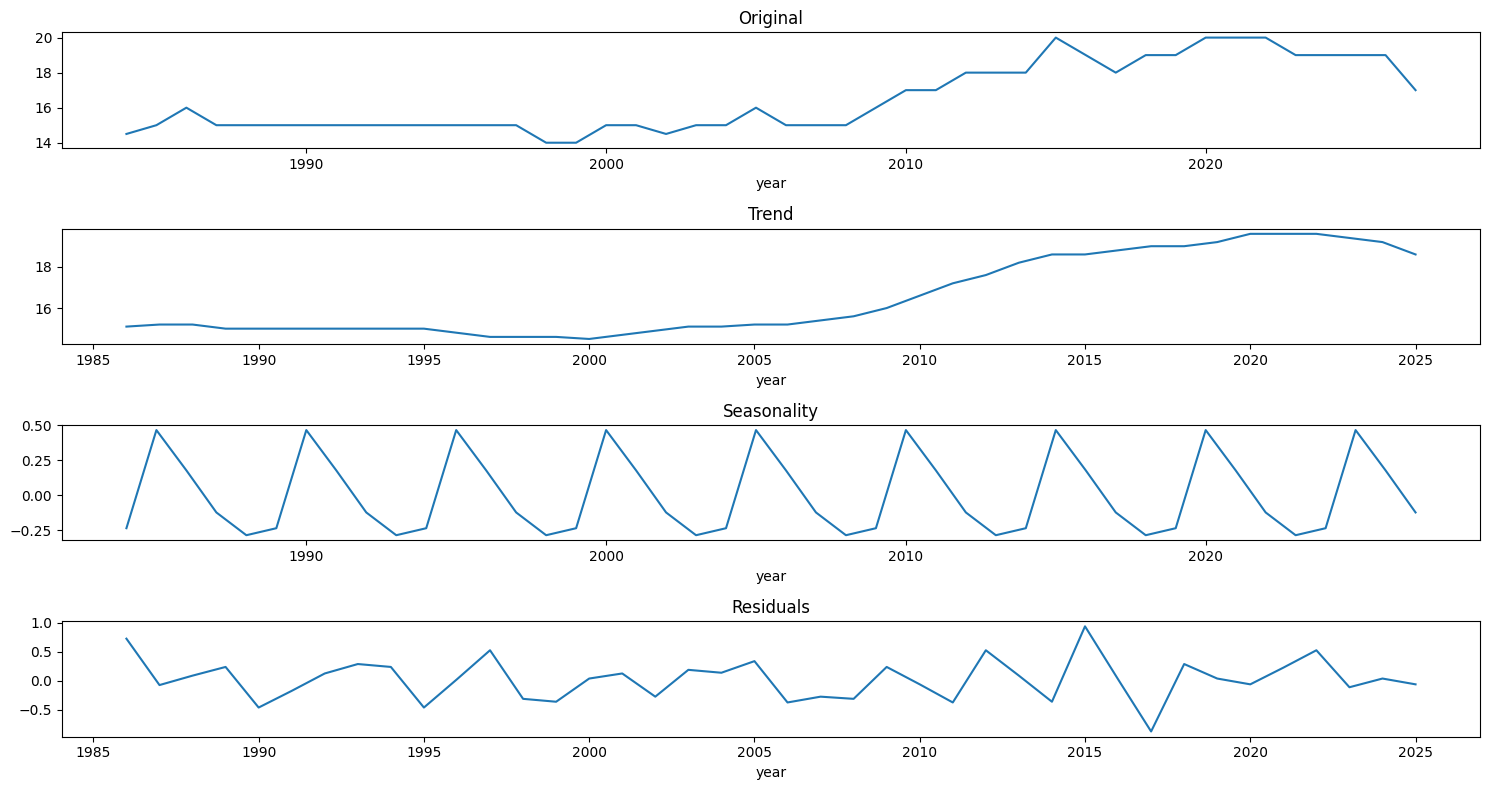

In [ ]:
# example of 5 year decomposition (period=5 on yearly data)
from matplotlib import pyplot as plt
decomposition = seasonal_decompose(ford, model='additive', period=5)

# Plot the decomposition
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(15, 8))
ford.plot(ax=ax1, title='Original')
decomposition.trend.plot(ax=ax2, title='Trend')
decomposition.seasonal.plot(ax=ax3, title='Seasonality')
decomposition.resid.plot(ax=ax4, title='Residuals')
fig.tight_layout()

In [ ]:
import pandas as pd
import numpy as np
from statsmodels.tsa.seasonal import seasonal_decompose

def get_seasonal(group, time_col, agg_col, period=1):
    # Sort by date and set index
    group = group.sort_values(time_col)
    # rename index to index
    group.index.name = 'index'
    ts = group.set_index(time_col)[agg_col]

    # Handle groups with insufficient data
    if len(ts) < 2:
        return group.assign(seasonal=0, trend=0, resid=0)

    # Decompose the time series
    res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')

    # Reassign the decomposed components to the group
    return (group
            .assign(seasonal=res.seasonal.values,
                    trend=res.trend.values,
                    resid=res.resid.values))

def add_seasonal(df, time_col, group_cols, agg_col):
    all_group_cols = [time_col] + group_cols
    return (df
            .groupby(group_cols)
            .apply(get_seasonal, time_col=time_col, agg_col=agg_col, period=1)
            .drop(columns=group_cols)
            .reset_index(drop=False)
            .set_index('index')
            .loc[df.index]
    )


# Example usage
res = add_seasonal(X, 'year', ['make'], agg_col='barrels08')

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

In [ ]:
res.iloc[:, -5:]

,fuelType,trans_dscr,seasonal,trend,resid
0,Regular,NaN,0.0,14.167143,0.0
1,Regular,NaN,0.0,27.046364,0.0
2,Regular,SIL,0.0,11.018889,0.0
3,Regular,NaN,0.0,27.046364,0.0
4,Premium,NaN,0.0,15.658421,0.0
...,...,...,...,...,...
50642,Regular,CLKUP,0.0,13.523182,0.0
50643,Regular,NaN,0.0,12.935217,0.0
50644,Regular,CLKUP,0.0,14.167143,0.0
50645,Regular,NaN,0.0,14.167143,0.0


In [ ]:
# Create Pipeline wtih Aggregation
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

# create the seasonal transformer
class SeasonTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, time_col, group_cols, agg_col):
        self.time_col = time_col
        self.group_cols = group_cols
        self.agg_col = agg_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return add_seasonal(X, self.time_col, self.group_cols, self.agg_col)


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
        ('seasonal_decompose', SeasonTransformer(time_col='year', group_cols=['make'], agg_col='barrels08')),
#          ['year', 'make',
#           'barrels08']),  # need to make sure we pass all columns needed

    ('preprocessor', preprocessor),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),

    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('seasonal_decompose',
                 SeasonTransformer(agg_col='barrels08', group_cols=['make'],
                                   time_col='year')),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=...
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf427187920>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline.score(X_test, y_test)

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

0.9529951843386257

#Data for Challenge

In [ ]:
!pip install openpyxl

In [ ]:
# create a model to predict monthly airline passgengers from https://www.transtats.bts.gov/Data_Elements.aspx?Data=1
# for some reason this output is not Excel but HTML
airlines = pd.read_html('data/Passengers_2024.xls')
raw = airlines[0]

/tmp/ipykernel_358/2035402763.py:3: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  airlines = pd.read_html('data/Passengers_2024.xls')


ValueError: No tables found

In [ ]:
# the code errors so I put some tweaks
import os

for root, dirs, files in os.walk('/content'):
    for file in files:
        if 'Passengers' in file:
            print(os.path.join(root, file))

import pandas as pd

airlines = pd.read_html(
    '/content/applied-machine-learning-feature-engineering-3809062-main/data/Passengers_2024.xls'
)

raw = airlines[0]

/content/applied-machine-learning-feature-engineering-3809062-main/data/Passengers_2024.xls


In [ ]:
raw

,Year,Month,DOMESTIC,INTERNATIONAL,TOTAL
0,2002,10,48054917,9578435,57633352
1,2002,11,44850246,9016535,53866781
2,2002,12,49684353,10038794,59723147
3,2002,TOTAL,551899643,118704850,670604493
4,2003,1,43032450,9726436,52758886
...,...,...,...,...,...
270,2023,7,75379256,23475990,98855246
271,2023,8,71478927,21664464,93143391
272,2023,9,66860476,18974545,85835021
273,2023,10,73035601,19095536,92131137


In [ ]:
def tweak_airline(df_):
  return (df_
          .query('Month != "TOTAL"')
          .astype({'Month': 'int64'})
          .assign(date=lambda df: pd.to_datetime(df[['Year', 'Month']].assign(day=1)))
  )

air = tweak_airline(raw)

In [ ]:
air.dtypes

,0
Year,int64
Month,int64
DOMESTIC,int64
INTERNATIONAL,int64
TOTAL,int64
date,datetime64[ns]


In [ ]:
air

,Year,Month,DOMESTIC,INTERNATIONAL,TOTAL,date
0,2002,10,48054917,9578435,57633352,2002-10-01
1,2002,11,44850246,9016535,53866781,2002-11-01
2,2002,12,49684353,10038794,59723147,2002-12-01
4,2003,1,43032450,9726436,52758886,2003-01-01
5,2003,2,41166780,8283372,49450152,2003-02-01
...,...,...,...,...,...,...
269,2023,6,72484376,21928411,94412787,2023-06-01
270,2023,7,75379256,23475990,98855246,2023-07-01
271,2023,8,71478927,21664464,93143391,2023-08-01
272,2023,9,66860476,18974545,85835021,2023-09-01


#Challenge: Temporal Features
Using the airline data, create a linear regression model to predict the number of passengers for the next month based on the current month.

Then make another model using the seasonal_decompose function to add a seasonality component to the model. How do the models compare?

# Solution: Temporal Features


In [ ]:
X = air[['DOMESTIC']].iloc[:-1]
y = air['DOMESTIC'].shift(-1).iloc[:-1]

#split data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

#create a linear regression model
lr = LinearRegression()
lr.fit(X_train, y_train)
lr.score(X_test, y_test)



0.7463371316870792

<Axes: xlabel='date'>

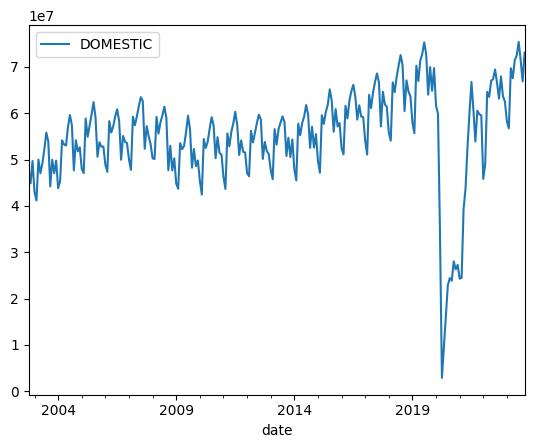

In [ ]:
(air
 .plot(x='date', y='DOMESTIC'))

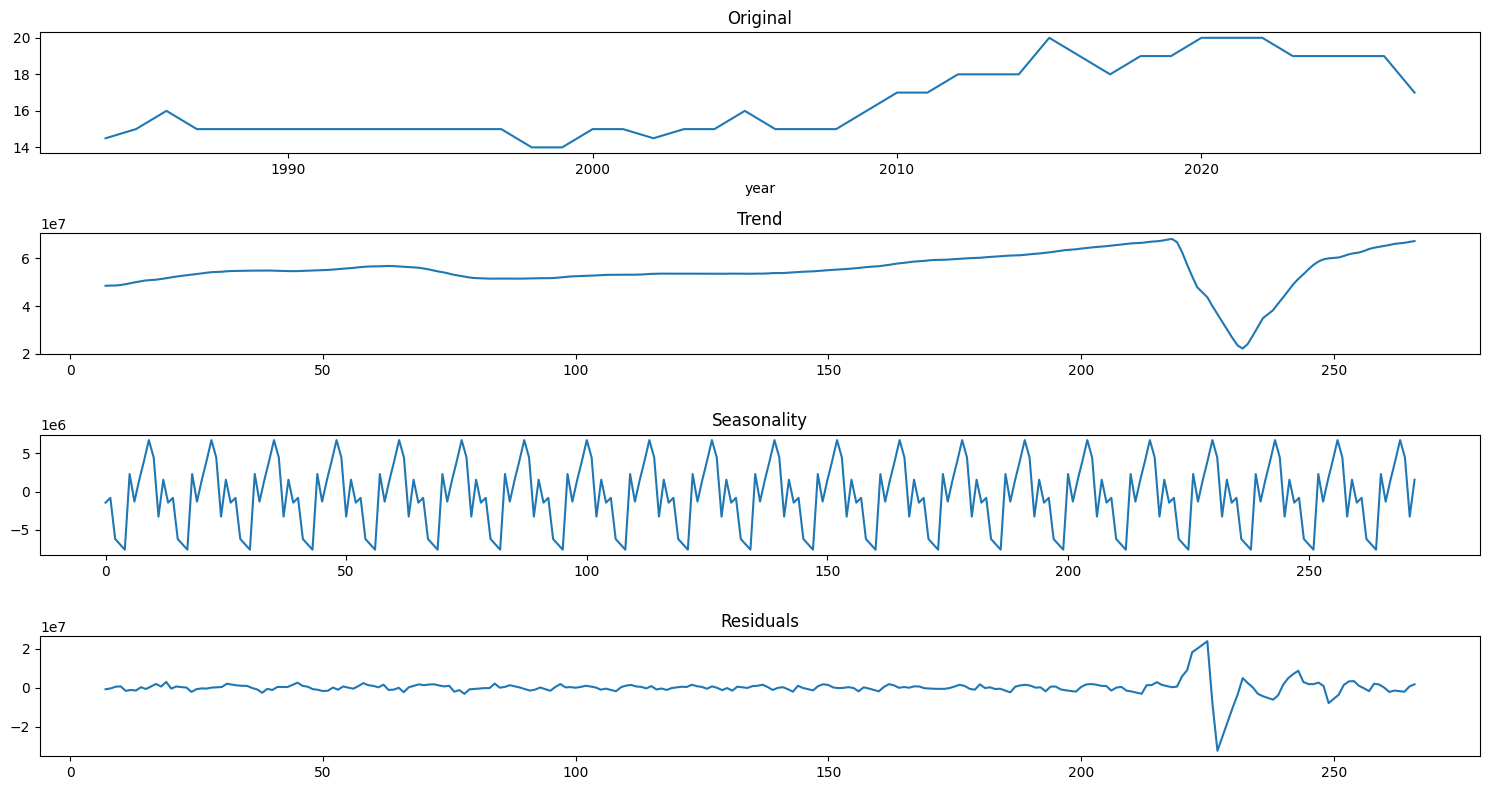

In [ ]:
decomposition = seasonal_decompose(y, model='additive', period=12)#perion means every 12 years

# Plot the decomposition
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(15, 8))
ford.plot(ax=ax1, title='Original')
decomposition.trend.plot(ax=ax2, title='Trend')
decomposition.seasonal.plot(ax=ax3, title='Seasonality')
decomposition.resid.plot(ax=ax4, title='Residuals')
fig.tight_layout()

In [ ]:
X=(air
   .assign(
       trend = lambda df: seasonal_decompose(df['DOMESTIC'], model='additive', period=12).trend,
       seasonal = lambda df: seasonal_decompose(df['DOMESTIC'], model='additive', period=12).seasonal,
       resid = lambda df: seasonal_decompose(df['DOMESTIC'], model='additive', period=12).resid
   )
   .loc[:, ['trend', 'seasonal', 'resid', 'DOMESTIC']]
   .iloc[12:-12]
   )

y = air['DOMESTIC'].shift(-1).loc[X.index]

#split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

#create the linear regression model
lr = LinearRegression()
lr.fit(X_train, y_train)
lr.score(X_test, y_test)

0.7024454535879184

#Feature Selection
Feature selection is the process of selecting a subset of features that are most relevant to the target variable. There are many reasons to do this:

- Simplicity - Fewer features are easier to interpret.
- Memory - Fewer features require less memory to store and less computation.
- Speed - Fewer features result in faster algorithms.

There are many techniques for feature selection. We will cover a few of them here:

- Feature importance
- Recursive feature elimination
#Feature Importance and Weights
Many models can provide a feature importance or weight for each feature. This is a measure of how much the model depends on that feature. We can use this to select the most important features.

In [ ]:
# Create Pipeline wtih Aggregation
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

# create the seasonal transformer
class SeasonTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, time_col, group_cols, agg_col):
        self.time_col = time_col
        self.group_cols = group_cols
        self.agg_col = agg_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return add_seasonal(X, self.time_col, self.group_cols, self.agg_col)


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
        ('seasonal_decompose', SeasonTransformer(time_col='year', group_cols=['make'], agg_col='barrels08')),
#          ['year', 'make',
#           'barrels08']),  # need to make sure we pass all columns needed

    ('preprocessor', preprocessor),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),

    #  ('minmax_scaler', minmax_scaler, ['range']),
    ('lr', LinearRegression())])

# fit the pipeline
pipeline.fit(X_train, y_train)

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('seasonal_decompose',
                 SeasonTransformer(agg_col='barrels08', group_cols=['make'],
                                   time_col='year')),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=...
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf427187ba0>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline

Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('seasonal_decompose',
                 SeasonTransformer(agg_col='barrels08', group_cols=['make'],
                                   time_col='year')),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=...
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf427187ba0>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
pipeline.fit(X_train, y_train)

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('seasonal_decompose',
                 SeasonTransformer(agg_col='barrels08', group_cols=['make'],
                                   time_col='year')),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=...
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf427187ba0>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler()), ('lr', LinearRegression())])

In [ ]:
# get linear regression model

lr = pipeline.named_steps['lr']
lr

LinearRegression()

In [ ]:

lr.feature_names_in_

array(['cyl_imputer__cylinders', 'displ_imputer__displ',
       'one_hot_encoder__VClass_Large Cars',
       'one_hot_encoder__VClass_Midsize Cars',
       'one_hot_encoder__VClass_Small Sport Utility Vehicle 4WD',
       'one_hot_encoder__VClass_Sport Utility Vehicle - 4WD',
       'one_hot_encoder__VClass_Standard Pickup Trucks',
       'one_hot_encoder__VClass_Standard Sport Utility Vehicle 4WD',
       'one_hot_encoder__VClass_Subcompact Cars',
       'one_hot_encoder__VClass_Two Seaters',
       'one_hot_encoder__VClass_infrequent_sklearn',
       'one_hot_encoder__drive_4-Wheel Drive',
       'one_hot_encoder__drive_4-Wheel or All-Wheel Drive',
       'one_hot_encoder__drive_All-Wheel Drive',
       'one_hot_encoder__drive_Front-Wheel Drive',
       'one_hot_encoder__drive_Part-time 4-Wheel Drive',
       'one_hot_encoder__drive_Rear-Wheel Drive',
       'one_hot_encoder__drive_nan',
       'one_hot_encoder__fuelType_Electricity',
       'one_hot_encoder__fuelType_Gasoline or E85

In [ ]:
pd.Series(lr.coef_, index=lr.feature_names_in_)

,0
cyl_imputer__cylinders,0.251628
displ_imputer__displ,-0.096626
one_hot_encoder__VClass_Large Cars,-0.070944
one_hot_encoder__VClass_Midsize Cars,0.112359
one_hot_encoder__VClass_Small Sport Utility Vehicle 4WD,0.272734
one_hot_encoder__VClass_Sport Utility Vehicle - 4WD,-0.001245
one_hot_encoder__VClass_Standard Pickup Trucks,0.087729
one_hot_encoder__VClass_Standard Sport Utility Vehicle 4WD,-0.148028
one_hot_encoder__VClass_Subcompact Cars,0.114600
one_hot_encoder__VClass_Two Seaters,0.135495


<Axes: >

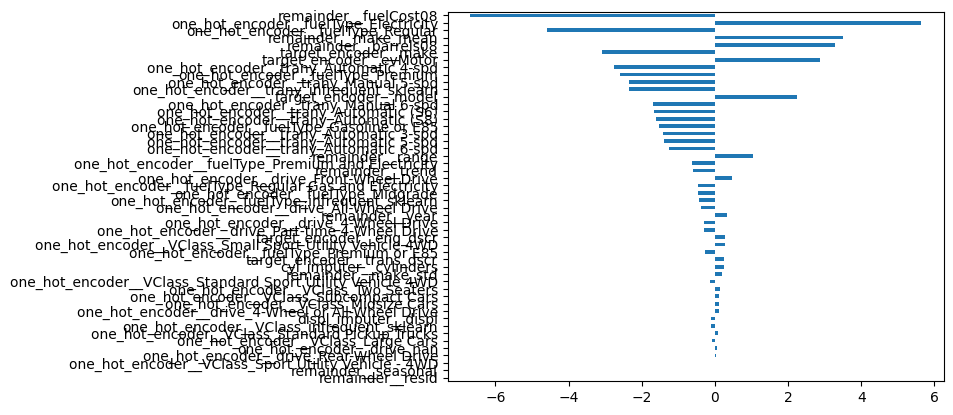

In [ ]:
(pd.Series(lr.coef_, index=lr.feature_names_in_)
 .sort_values(key=abs)
 .plot.barh()
)

In [ ]:
len(lr.feature_names_in_)

50

<Axes: >

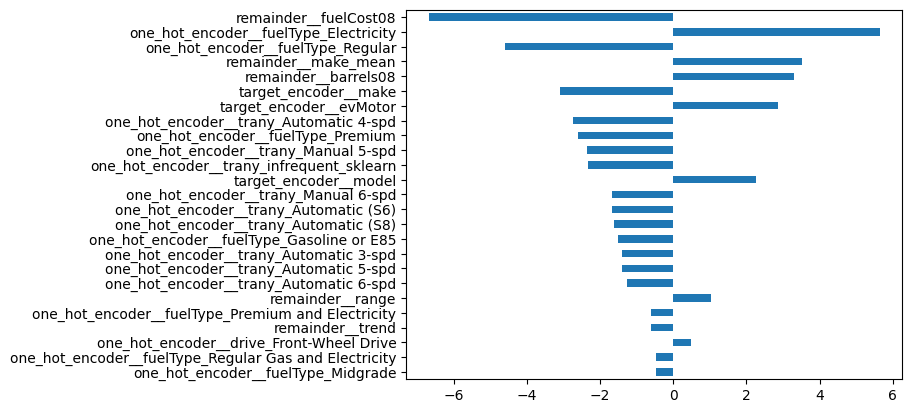

In [ ]:
(pd.Series(lr.coef_, index=lr.feature_names_in_)
 .sort_values(key=abs)
 .tail(25)
 .plot.barh()
)

<Axes: >

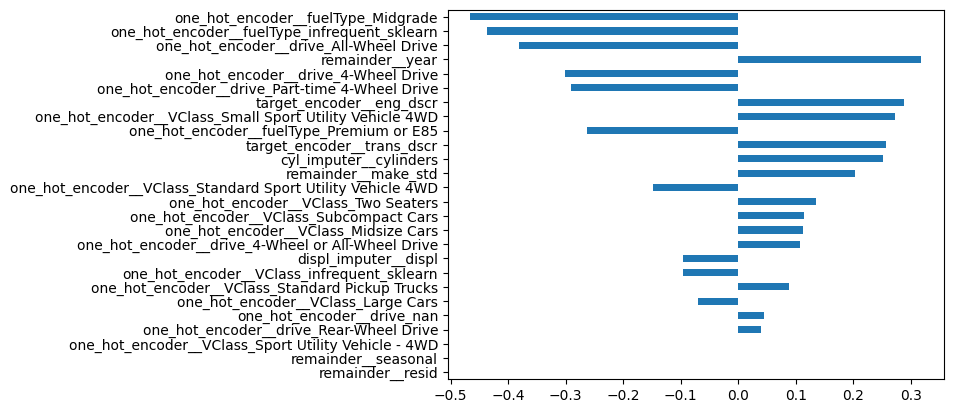

In [ ]:
# note scale of x axis
(pd.Series(lr.coef_, index=lr.feature_names_in_)
 .sort_values(key=abs)
 .head(26)
 .plot.barh()
)

In [ ]:
!pip install xgboost

In [ ]:
# use xgboost to make a model and then get feature importances
import xgboost as xgb

# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X.assign(**X.select_dtypes(object).astype('category')),
    y, random_state=42)

xg = xgb.XGBRegressor(enable_categorical=True, random_state=42)
xg.fit(X_train, y_train)
xg.score(X_test, y_test)

0.995961606502533

<Axes: >

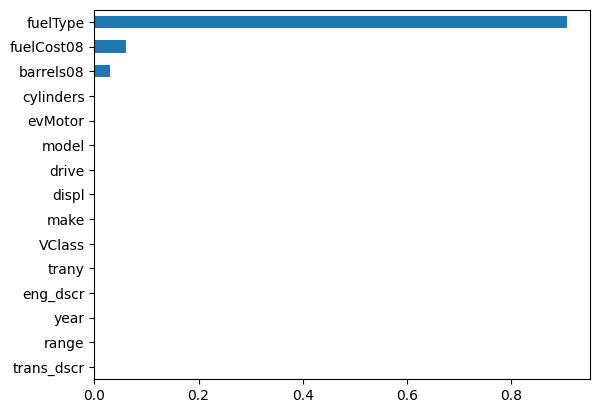

In [ ]:
pd.Series(xg.feature_importances_, index=X_train.columns).sort_values().tail(25).plot.barh()

<Axes: xlabel='range', ylabel='city08'>

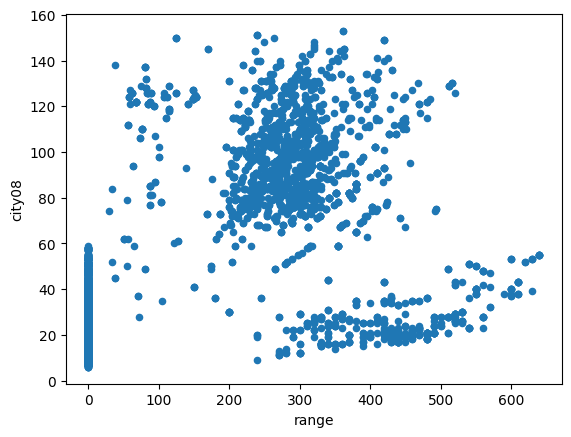

In [ ]:
# scatter plot range vs city mpg
(autos
 .plot.scatter(x='range', y='city08')
)

<Axes: >

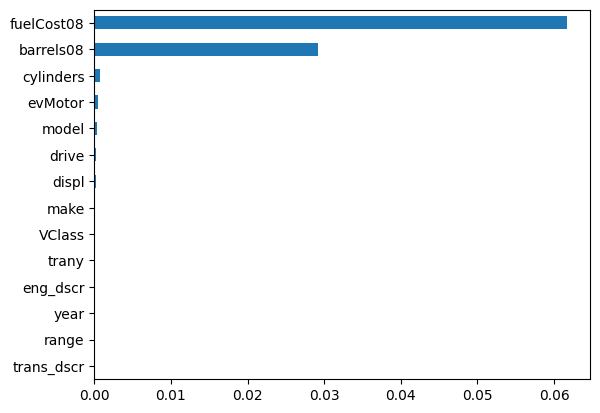

In [ ]:
pd.Series(xg.feature_importances_, index=X_train.columns).sort_values().iloc[:-1].plot.barh()

In [ ]:
# make xg model with just range, barrels08, fuelType, and cylinders
xg_simple = xgb.XGBRegressor(enable_categorical=True, random_state=42)
xg_simple.fit(X_train[['range', 'barrels08', 'fuelType', 'cylinders']], y_train)
xg_simple.score(X_test[['range', 'barrels08', 'fuelType', 'cylinders']], y_test)

0.995421826839447

# Recursive Feature Elimination
Recursive feature elimination (RFE) is a feature selection method that fits a model and removes the weakest feature (or features) until the specified number of features is reached. It is a greedy optimization algorithm that aims to find the best performing feature subset.

In [ ]:
from sklearn.feature_selection import RFE

# use rfe with xgboost
xg_model = xgb.XGBRegressor(enable_categorical=True, random_state=42)
rfe = RFE(xg_model, n_features_to_select=3)

X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    #X.assign(**X.select_dtypes('string[pyarrow]').astype('category')),
    X.select_dtypes('number'),
    y, random_state=42)

rfe.fit(X_train, y_train)

RFE(estimator=XGBRegressor(base_score=None, booster=None, callbacks=None,
                           colsample_bylevel=None, colsample_bynode=None,
                           colsample_bytree=None, device=None,
                           early_stopping_rounds=None, enable_categorical=True,
                           eval_metric=None, feature_types=None,
                           feature_weights=None, gamma=None, grow_policy=None,
                           importance_type=None, interaction_constraints=None,
                           learning_rate=None, max_bin=None,
                           max_cat_threshold=None, max_cat_to_onehot=None,
                           max_delta_step=None, max_depth=None, max_leaves=None,
                           min_child_weight=None, missing=nan,
                           monotone_constraints=None, multi_strategy=None,
                           n_estimators=None, n_jobs=None,
                           num_parallel_tree=None, ...),
    n_features_to_select=3)

In [ ]:
# Explore the API to determine which features were selected
rfe?

In [ ]:
pd.DataFrame({'features':X_train.columns,
              'support': rfe.support_,
              'ranking':rfe.ranking_}).sort_values('ranking')

,features,support,ranking
1,barrels08,True,1
4,displ,True,1
5,fuelCost08,True,1
3,cylinders,False,2
2,range,False,3
0,year,False,4


In [ ]:
# make model with barrels08, range, and fuelCost08
xg_simple = xgb.XGBRegressor(enable_categorical=True, random_state=42)
xg_simple.fit(X_train[['barrels08', 'range', 'fuelCost08']], y_train)
xg_simple.score(X_test[['barrels08', 'range', 'fuelCost08']], y_test)

0.9963273406028748


# Adding a Random Column
Another technique is to add a column of random numbers. We should be able to drop any columns that perform worse than the random column.

In [ ]:
# create X and add a random column
X = (autos
     .drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
     .assign(random=lambda df: np.random.random(size=len(df)))
     )

y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X.assign(**X.select_dtypes(object).astype('category')),
    y, random_state=42)

xg = xgb.XGBRegressor(enable_categorical=True, random_state=42)
xg.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

<Axes: >

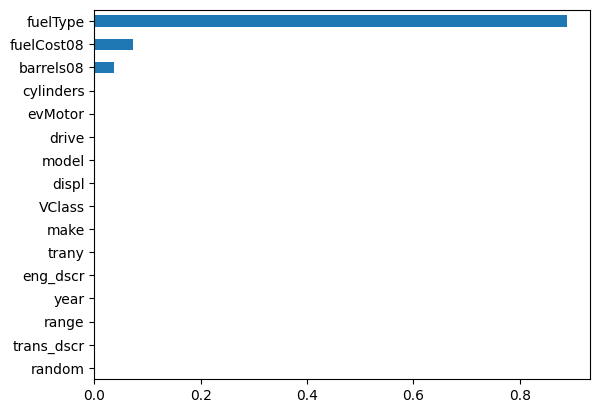

In [ ]:
# look at feature importances
# In this case the random column is the least important
pd.Series(xg.feature_importances_, index=X_train.columns).sort_values().plot.barh()

#Challenge: Feature Selection
Apply RFE to linear regression model to limit model to 5 columns
#Solution: Feature Selection

In [ ]:
# Create Pipeline wtih Aggregation
from sklearn.decomposition import PCA
# replace hashing encoder with target encoder for high cardinality columns

from category_encoders import hashing
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import FunctionTransformer, StandardScaler, MinMaxScaler, OneHotEncoder, TargetEncoder


# create X and y
X = autos.drop(columns=['city08', 'highway08', 'comb08', 'createdOn', 'offset', 'str_date'])
y = autos.city08

# split into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# create pipeline fill cylinders with 0 and displ with median

cylinders_imputer = SimpleImputer(strategy='constant', fill_value=0)
displ_imputer = SimpleImputer(strategy='median')
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()
cat_imputer = SimpleImputer(strategy='constant', fill_value='missing')
one_hot_encoder = OneHotEncoder(drop='first', max_categories=10, sparse_output=False, handle_unknown='ignore')
hashing_encoder = hashing.HashingEncoder(n_components=10, drop_invariant=True)
target_encoder = TargetEncoder(target_type='continuous', random_state=42)

def debug_transformer(X, name):
    globals()[name] = X
    return X

cat_cols =  ['make', 'model', 'trany', 'drive',
            'VClass', 'eng_dscr', 'evMotor', 'fuelType', 'trans_dscr', ]
low_cardinality_cols = ['VClass', 'drive', 'fuelType', 'trany']
high_cardinality_cols = ['make', 'model', 'eng_dscr', 'evMotor', 'trans_dscr']

# create the seasonal transformer
class SeasonTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, time_col, group_cols, agg_col):
        self.time_col = time_col
        self.group_cols = group_cols
        self.agg_col = agg_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return add_seasonal(X, self.time_col, self.group_cols, self.agg_col)


# Create the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('cyl_imputer', cylinders_imputer, ['cylinders']),
        ('displ_imputer', displ_imputer, ['displ']),
        ('one_hot_encoder', one_hot_encoder, low_cardinality_cols),
        #('hashing_encoder', hashing_encoder, high_cardinality_cols)
        ('target_encoder', target_encoder, high_cardinality_cols),
    ],
    remainder='passthrough'
)

# pipeline
pipeline = Pipeline(steps=[
    ('string_converter', PyArrowStringConverter()),
    ('make_mean_std', AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
        ('seasonal_decompose', SeasonTransformer(time_col='year', group_cols=['make'], agg_col='barrels08')),
#          ['year', 'make',
#           'barrels08']),  # need to make sure we pass all columns needed

    ('preprocessor', preprocessor),
    ('debug', FunctionTransformer(debug_transformer, kw_args={'name': 'tmp_X'})),
    ('std_scaler', std_scaler),
    #('pca', PCA(n_components=10)),

    #  ('minmax_scaler', minmax_scaler, ['range']),
    # ('lr', LinearRegression())
    ])

# fit the pipeline
pipeline.fit(X_train, y_train)

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

Pipeline(steps=[('string_converter', PyArrowStringConverter()),
                ('make_mean_std',
                 AddMeanStd(col='make', missing_mean_val=0, missing_std_val=0)),
                ('seasonal_decompose',
                 SeasonTransformer(agg_col='barrels08', group_cols=['make'],
                                   time_col='year')),
                ('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cyl_imputer',
                                                  SimpleImputer(fill_value=...
                                                                handle_unknown='ignore',
                                                                max_categories=10,
                                                                sparse_output=False),
                                                  ['VClass', 'drive',
                                                   'fuelType', 'trany']),
                                                 ('target_encoder',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['make', 'model', 'eng_dscr',
                                                   'evMotor',
                                                   'trans_dscr'])])),
                ('debug',
                 FunctionTransformer(func=<function debug_transformer at 0x7cf415b49120>,
                                     kw_args={'name': 'tmp_X'})),
                ('std_scaler', StandardScaler())])

In [ ]:
lr = LinearRegression()
rfe = RFE(lr, n_features_to_select=5)
rfe.fit(pipeline.transform(X_train), y_train)


/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

RFE(estimator=LinearRegression(), n_features_to_select=5)

In [ ]:
pd.DataFrame({'features':pipeline.transform(X_train).columns,
              'support': rfe.support_,
              'ranking':rfe.ranking_}).sort_values('ranking')

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

,features,support,ranking
24,one_hot_encoder__fuelType_Regular,True,1
21,one_hot_encoder__fuelType_Premium,True,1
37,target_encoder__model,True,1
39,target_encoder__evMotor,True,1
44,remainder__fuelCost08,True,1
19,one_hot_encoder__fuelType_Gasoline or E85,False,2
43,remainder__range,False,3
45,remainder__make_mean,False,4
36,target_encoder__make,False,5
20,one_hot_encoder__fuelType_Midgrade,False,6


#Continuation of the Challenge
What we'll do next
1. Identify the five features selected by RFE.
2. Train a Linear Regression model using only those five features.
3. Compare its performance against the original model.
4. Optionally compare both models with XGBoost to see whether it performs better.

/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolate_trend='freq')
/tmp/ipykernel_358/4163569392.py:17: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  res = seasonal_decompose(ts, model='additive', period=period, extrapolat

RFE Selected Features:
 - one_hot_encoder__fuelType_Premium
 - one_hot_encoder__fuelType_Regular
 - target_encoder__model
 - target_encoder__evMotor
 - remainder__fuelCost08

MODEL PERFORMANCE
            Model  R2 Score   RMSE
Linear Regression    0.7880 7.3492
          XGBoost    0.9543 3.4117


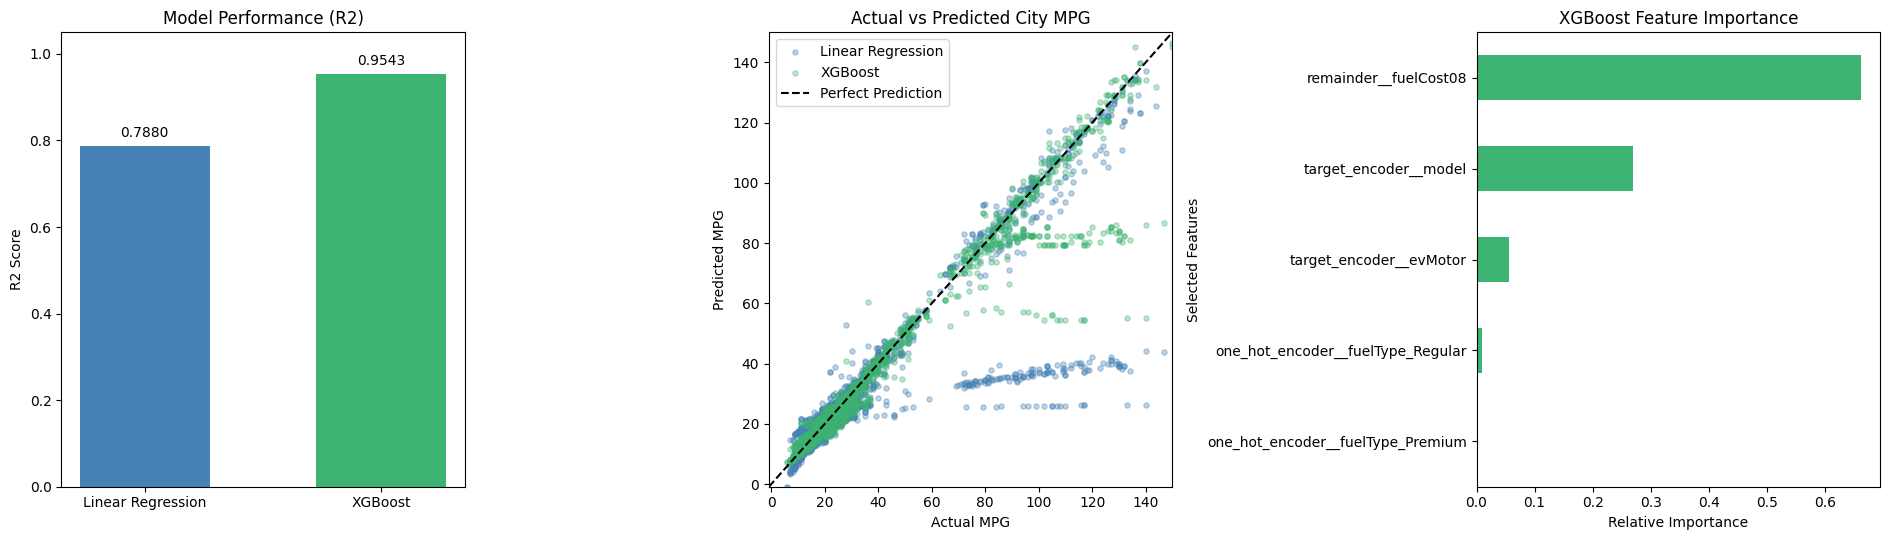


BEST MODEL: XGBoost
R2 Score: 0.9543
RMSE: 3.4117
Number of Features: 5


In [ ]:

# If XGBoost is not installed, run this once:
# %pip install xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# ==========================================
# STEP 1: GET THE FIVE FEATURES FROM RFE
# ==========================================

selected_features = pipeline.transform(X_train).columns[rfe.support_].tolist()

X_train_processed = pipeline.transform(X_train)
X_test_processed = pipeline.transform(X_test)

X_train_5 = X_train_processed[selected_features]
X_test_5 = X_test_processed[selected_features]

print("RFE Selected Features:")
for feature in selected_features:
    print(" -", feature)

# ==========================================
# STEP 2: TRAIN BOTH MODELS
# ==========================================

linear_model = LinearRegression()
linear_model.fit(X_train_5, y_train)

xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

xgb_model.fit(X_train_5, y_train)

# Predictions
linear_pred = linear_model.predict(X_test_5)
xgb_pred = xgb_model.predict(X_test_5)

# ==========================================
# STEP 3: CALCULATE PERFORMANCE
# ==========================================

results = pd.DataFrame({
    "Model": ["Linear Regression", "XGBoost"],
    "R2 Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, xgb_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_pred)),
        np.sqrt(mean_squared_error(y_test, xgb_pred))
    ]
})

print("\nMODEL PERFORMANCE")
print(results.round(4).to_string(index=False))

# ==========================================
# STEP 4: PLOT THE RESULTS
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

# CHART 1: R2 SCORE COMPARISON
bars = axes[0].bar(
    results["Model"],
    results["R2 Score"],
    color=["steelblue", "mediumseagreen"],
    width=0.55
)

axes[0].set_title("Model Performance (R2)")
axes[0].set_ylabel("R2 Score")
axes[0].set_ylim(0, max(1, results["R2 Score"].max() * 1.1))
axes[0].bar_label(bars, fmt="%.4f", padding=4)

# CHART 2: ACTUAL VS PREDICTED MPG
axes[1].scatter(
    y_test, linear_pred,
    alpha=0.35, s=14,
    label="Linear Regression",
    color="steelblue"
)

axes[1].scatter(
    y_test, xgb_pred,
    alpha=0.35, s=14,
    label="XGBoost",
    color="mediumseagreen"
)

limits = [
    min(y_test.min(), linear_pred.min(), xgb_pred.min()),
    max(y_test.max(), linear_pred.max(), xgb_pred.max())
]

axes[1].plot(
    limits, limits, "k--",
    linewidth=1.5,
    label="Perfect Prediction"
)

axes[1].set_xlim(limits)
axes[1].set_ylim(limits)
axes[1].set_title("Actual vs Predicted City MPG")
axes[1].set_xlabel("Actual MPG")
axes[1].set_ylabel("Predicted MPG")
axes[1].legend()

# CHART 3: XGBOOST FEATURE IMPORTANCE
importance = pd.Series(
    xgb_model.feature_importances_,
    index=selected_features
).sort_values()

importance.plot.barh(
    ax=axes[2],
    color="mediumseagreen"
)

axes[2].set_title("XGBoost Feature Importance")
axes[2].set_xlabel("Relative Importance")
axes[2].set_ylabel("Selected Features")

plt.tight_layout()
plt.show()

# ==========================================
# STEP 5: DISPLAY THE WINNER
# ==========================================

best_model = results.loc[results["R2 Score"].idxmax()]

print("\nBEST MODEL:", best_model["Model"])
print("R2 Score:", round(best_model["R2 Score"], 4))
print("RMSE:", round(best_model["RMSE"], 4))
print("Number of Features:", len(selected_features))


### Conclusion: What I Learned

In this activity, I learned how to use Recursive Feature Elimination (RFE) to select five features from a dataset. At first, I was confused about how feature selection works, but after trying it and comparing the results, I started to understand its purpose.

I also tried using Linear Regression and XGBoost to see how different models perform using the same five features. Based on the results, XGBoost performed better than Linear Regression. The graphs helped me understand the differences between their predictions.

Although I still don't fully understand all the concepts and how the algorithms work, this activity helped me become more familiar with feature selection, model comparison, and evaluating results.

Overall, I learned that machine learning involves experimenting, comparing results, and understanding why some models perform better than others. I still have a lot to learn, but this activity gave me a better understanding of how these techniques are applied in practice.